# GameTheory-14 : Jeux Differentiels et Equilibres de Stackelberg

**Navigation** : [<< 13-ImperfectInfo-CFR](GameTheory-13-ImperfectInfo-CFR-Python.ipynb) | [Index](README.md) | [15-CooperativeGames >>](GameTheory-15-CooperativeGames-Python.ipynb)

**Side tracks** : [14b-Jeux-Repetes-Tournoi-Axelrod](GameTheory-14b-Jeux-Repetes-Tournoi-Axelrod-Python.ipynb)

## Decisions Dynamiques et Leadership Stratégique

Ce notebook introduit les **jeux differentiels** (decisions continues dans le temps) et les **equilibres de Stackelberg** (modèles leader-follower).

### Objectifs d'apprentissage

- Comprendre la différence entre boucle ouverte et boucle fermee
- Maitriser les equilibres de Stackelberg
- Analyser les jeux lineaires-quadratiques (LQ)
- Appliquer a l'economie industrielle (oligopoles dynamiques)

### Prerequis

- Notebooks 1-12, notions de calcul differentiel

### Duree estimee : 60 minutes

***

## 1. Introduction aux Jeux Dynamiques

### 1.1 Jeux statiques vs dynamiques

| Aspect | Jeux statiques | Jeux dynamiques |
|--------|----------------|------------------|
| **Temps** | Une seule periode | Plusieurs periodes ou continu |
| **Actions** | Simultanees | Séquentielles ou continues |
| **Etat** | Fixe | Evolue selon les actions |
| **Information** | Connue a l'avance | Revelee progressivement |

### 1.2 Types de stratégies

- **Boucle ouverte (open-loop)** : le joueur s'engage sur une trajectoire complete $u(t)$ au debut
- **Boucle fermee (closed-loop/feedback)** : le joueur ajuste sa stratégie $u(x(t), t)$ selon l'etat courant

### 1.3 Historique

Les jeux differentiels ont ete formalises par **Rufus Isaacs** (1965) dans le contexte de problemes de poursuite-evasion militaires.

In [1]:
# Installation des dependances
import subprocess
import sys

packages = ['numpy', 'scipy', 'matplotlib']
for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint, solve_ivp
from scipy.optimize import minimize, minimize_scalar
from typing import Tuple, Callable, List
from dataclasses import dataclass

print("Imports reussis")

Imports reussis


## 2. Equilibres de Stackelberg

### 2.1 Modèle Leader-Follower

Dans un jeu de Stackelberg :
1. Le **leader** choisit son action $x_L$ en premier
2. Le **follower** observe $x_L$ et choisit sa meilleure reponse $x_F(x_L)$
3. Le leader anticipe cette reaction et optimise en consequence

### 2.2 Resolution

**Étape 1** : Trouver la meilleure reponse du follower
$$x_F^*(x_L) = \arg\max_{x_F} \pi_F(x_L, x_F)$$

**Étape 2** : Le leader maximise en substituant
$$x_L^* = \arg\max_{x_L} \pi_L(x_L, x_F^*(x_L))$$

### 2.3 Comparaison avec Cournot

Dans le duopole de Cournot, les firmes choisissent simultanement. Dans Stackelberg, le leader a un **avantage du premier joueur**.

In [2]:
@dataclass
class LinearDemand:
    """Demande lineaire P(Q) = a - bQ."""
    a: float  # Intercept
    b: float  # Pente
    
    def price(self, Q: float) -> float:
        return max(0, self.a - self.b * Q)
    
    def __repr__(self):
        return f"P(Q) = {self.a} - {self.b}Q"


@dataclass
class Firm:
    """Firme avec cout marginal constant."""
    name: str
    marginal_cost: float
    
    def cost(self, q: float) -> float:
        return self.marginal_cost * q
    
    def profit(self, q: float, price: float) -> float:
        return (price - self.marginal_cost) * q


def cournot_equilibrium(demand: LinearDemand, 
                        firm1: Firm, firm2: Firm) -> Tuple[float, float]:
    """
    Calcule l'equilibre de Cournot pour un duopole.
    
    Retourne (q1*, q2*)
    """
    a, b = demand.a, demand.b
    c1, c2 = firm1.marginal_cost, firm2.marginal_cost
    
    # Fonctions de reaction
    # q1 = (a - c1 - b*q2) / (2*b)
    # q2 = (a - c2 - b*q1) / (2*b)
    
    # Resolution du systeme
    q1 = (a - 2*c1 + c2) / (3*b)
    q2 = (a - 2*c2 + c1) / (3*b)
    
    return max(0, q1), max(0, q2)


def stackelberg_equilibrium(demand: LinearDemand,
                            leader: Firm, follower: Firm) -> Tuple[float, float]:
    """
    Calcule l'equilibre de Stackelberg.
    
    Le leader choisit en premier, anticipant la reaction du follower.
    Retourne (q_leader*, q_follower*)
    """
    a, b = demand.a, demand.b
    c_L, c_F = leader.marginal_cost, follower.marginal_cost
    
    # Fonction de reaction du follower
    # q_F(q_L) = (a - c_F - b*q_L) / (2*b)
    
    # Le leader maximise pi_L(q_L, q_F(q_L))
    # pi_L = (a - b*(q_L + q_F) - c_L) * q_L
    # Substitution et derivation -> q_L* = (a - 2*c_L + c_F) / (2*b)
    
    q_L = (a - 2*c_L + c_F) / (2*b)
    q_F = (a - c_F - b*q_L) / (2*b)
    
    return max(0, q_L), max(0, q_F)


# Exemple numerique
demand = LinearDemand(a=100, b=1)
firm_A = Firm("A", marginal_cost=10)
firm_B = Firm("B", marginal_cost=10)

print("Duopole avec demande P(Q) = 100 - Q, couts marginaux c = 10")
print("="*60)

# Cournot
q1_c, q2_c = cournot_equilibrium(demand, firm_A, firm_B)
Q_c = q1_c + q2_c
P_c = demand.price(Q_c)
pi1_c = firm_A.profit(q1_c, P_c)
pi2_c = firm_B.profit(q2_c, P_c)

print(f"\nEquilibre de Cournot (simultane):")
print(f"  q_A = {q1_c:.2f}, q_B = {q2_c:.2f}")
print(f"  Q total = {Q_c:.2f}, Prix = {P_c:.2f}")
print(f"  Profits: pi_A = {pi1_c:.2f}, pi_B = {pi2_c:.2f}")

# Stackelberg avec A leader
q_L, q_F = stackelberg_equilibrium(demand, firm_A, firm_B)
Q_s = q_L + q_F
P_s = demand.price(Q_s)
pi_L = firm_A.profit(q_L, P_s)
pi_F = firm_B.profit(q_F, P_s)

print(f"\nEquilibre de Stackelberg (A leader):")
print(f"  q_A (leader) = {q_L:.2f}, q_B (follower) = {q_F:.2f}")
print(f"  Q total = {Q_s:.2f}, Prix = {P_s:.2f}")
print(f"  Profits: pi_A = {pi_L:.2f}, pi_B = {pi_F:.2f}")

print(f"\nAvantage du leader: {pi_L - pi1_c:.2f} (vs Cournot)")
print(f"Desavantage du follower: {pi_F - pi2_c:.2f} (vs Cournot)")

Duopole avec demande P(Q) = 100 - Q, couts marginaux c = 10

Equilibre de Cournot (simultane):
  q_A = 30.00, q_B = 30.00
  Q total = 60.00, Prix = 40.00
  Profits: pi_A = 900.00, pi_B = 900.00

Equilibre de Stackelberg (A leader):
  q_A (leader) = 45.00, q_B (follower) = 22.50
  Q total = 67.50, Prix = 32.50
  Profits: pi_A = 1012.50, pi_B = 506.25

Avantage du leader: 112.50 (vs Cournot)
Desavantage du follower: -393.75 (vs Cournot)


### Interpretation : Cournot vs Stackelberg

La comparaison numérique illustre l'**avantage du premier joueur** (first-mover advantage) :

| Equilibre | q_A | q_B | Q total | Prix | Profit A | Profit B |
|-----------|-----|-----|---------|------|----------|----------|
| **Cournot** | 30 | 30 | 60 | 40 | 900 | 900 |
| **Stackelberg** | 45 | 22.5 | 67.5 | 32.5 | 1012.50 | 506.25 |

**Analyse des résultats** :

1. **Le leader produit 50% de plus** (45 vs 30) car il s'engage sur une quantite elevee, forcant le follower a reduire sa production.

2. **Le follower subit une perte de 44%** (506.25 vs 900) malgre une stratégie optimale de sa part.

3. **Les consommateurs beneficient** : la quantite totale augmente (67.5 vs 60) et le prix baisse (32.5 vs 40).

4. **L'industrie perd globalement** : le profit total (1518.75) est inferieur au cas Cournot (1800) car le prix plus bas reduit les marges.

> **Paradoxe de Stackelberg** : Le leadership confere un avantage individuel, mais la competition plus intense reduit le profit collectif de l'industrie.

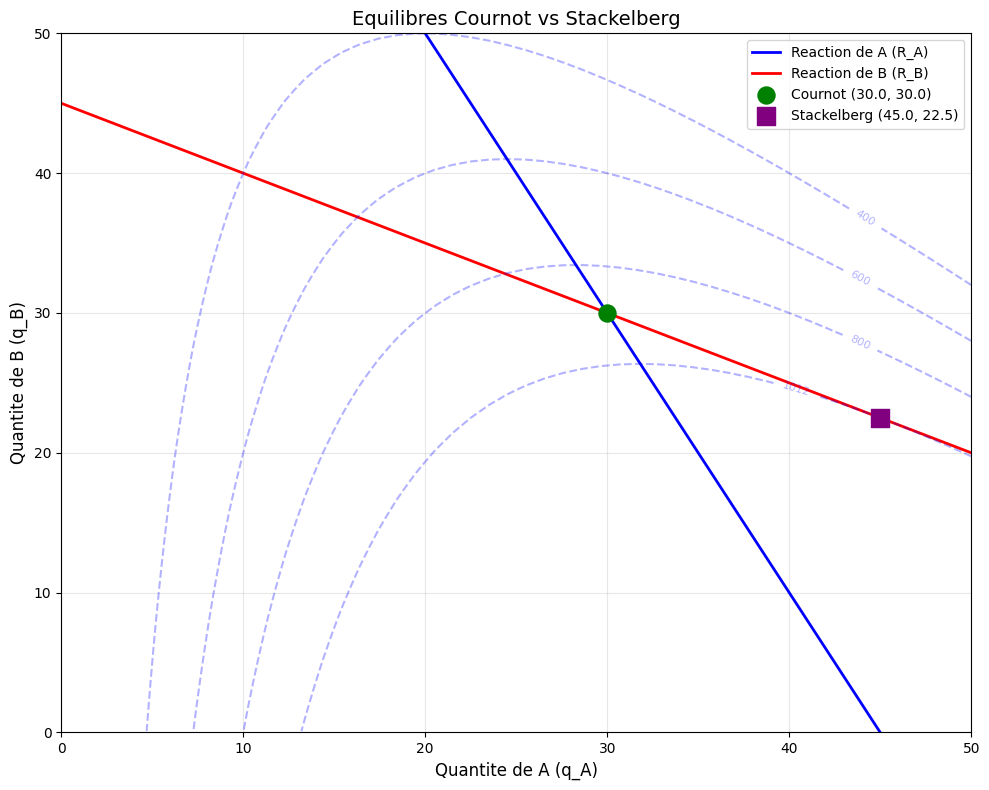

Figure sauvegardee: stackelberg_vs_cournot.png


In [3]:
# Visualisation : fonctions de reaction et equilibres
fig, ax = plt.subplots(figsize=(10, 8))

q_range = np.linspace(0, 50, 100)

# Fonction de reaction de A : q_A = (a - c_A - b*q_B) / (2*b)
def reaction_A(q_B):
    return max(0, (demand.a - firm_A.marginal_cost - demand.b * q_B) / (2 * demand.b))

def reaction_B(q_A):
    return max(0, (demand.a - firm_B.marginal_cost - demand.b * q_A) / (2 * demand.b))

# Tracer les fonctions de reaction
q_A_values = [reaction_A(q_B) for q_B in q_range]
q_B_values = [reaction_B(q_A) for q_A in q_range]

ax.plot(q_A_values, q_range, 'b-', linewidth=2, label="Reaction de A (R_A)")
ax.plot(q_range, q_B_values, 'r-', linewidth=2, label="Reaction de B (R_B)")

# Equilibre de Cournot
ax.scatter([q1_c], [q2_c], s=150, c='green', marker='o', zorder=5,
           label=f"Cournot ({q1_c:.1f}, {q2_c:.1f})")

# Equilibre de Stackelberg
ax.scatter([q_L], [q_F], s=150, c='purple', marker='s', zorder=5,
           label=f"Stackelberg ({q_L:.1f}, {q_F:.1f})")

# Isoprofits du leader (approximation)
q_A_grid = np.linspace(0.1, 50, 50)
q_B_grid = np.linspace(0.1, 50, 50)
Q_A, Q_B = np.meshgrid(q_A_grid, q_B_grid)
Profit_A = (demand.a - demand.b * (Q_A + Q_B) - firm_A.marginal_cost) * Q_A

# Contours d'isoprofit
contours = ax.contour(Q_A, Q_B, Profit_A, levels=[400, 600, 800, pi_L], 
                      colors='blue', alpha=0.3, linestyles='dashed')
ax.clabel(contours, inline=True, fontsize=8, fmt='%.0f')

ax.set_xlabel("Quantite de A (q_A)", fontsize=12)
ax.set_ylabel("Quantite de B (q_B)", fontsize=12)
ax.set_title("Equilibres Cournot vs Stackelberg", fontsize=14)
ax.set_xlim(0, 50)
ax.set_ylim(0, 50)
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('stackelberg_vs_cournot.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figure sauvegardee: stackelberg_vs_cournot.png")

### Interpretation geometrique : Fonctions de reaction et isoprofits

La figure montre la representation graphique classique du duopole :

**Fonctions de reaction (R_A et R_B)** :
- R_A (bleu) : quantite optimale de A pour chaque q_B
- R_B (rouge) : quantite optimale de B pour chaque q_A
- L'intersection = equilibre de Cournot (point vert, 30, 30)

**Isoprofits du leader (A)** :
- Courbes bleues en pointille : contours de profit constant pour A
- Plus on va vers le haut-gauche, plus le profit de A est eleve
- La pente de R_B en (30,30) montre comment A peut ameliorer son profit

**Equilibre de Stackelberg (point violet, 45, 22.5)** :
- Situe sur R_B : le follower B reagit optimalement au leader A
- A l'exterieur de R_A : A ne reagit pas a B (il s'engage en premier)
- Sur une courbe d'isoprofit plus elevee que Cournot

**Avantage du premier joueur** :
- En se deplacant de Cournot (30,30) vers Stackelberg (45,22.5), A "pousse" B a reduire sa production
- A sacrifie son profit de court terme pour s'engager sur une quantite elevee
- B est force de reduire sa production (22.5 vs 30) car sa fonction de reaction est decroissante

> **Insight stratégique** : Le leader "tire" l'equilibre le long de la fonction de reaction du follower, se placant sur une courbe d'isoprofit plus favorable.

## 3. Jeux Differentiels : Formalisation

### 3.1 Structure d'un jeu differentiel

Un jeu differentiel a $n$ joueurs est défini par :

- **Dynamique d'etat** : $\dot{x}(t) = f(x(t), u_1(t), ..., u_n(t), t)$
- **Condition initiale** : $x(0) = x_0$
- **Objectifs** : $J_i = \int_0^T g_i(x(t), u_1(t), ..., u_n(t), t) dt + \phi_i(x(T))$

### 3.2 Equilibre de Nash en boucle ouverte

Chaque joueur s'engage sur une trajectoire $u_i^*(t)$ pour $t \in [0, T]$ au debut du jeu.

**Condition d'equilibre** : Pour tout $i$, $u_i^*$ maximise $J_i$ etant donne $u_{-i}^*$.

### 3.3 Equilibre en boucle fermee (feedback)

Les joueurs utilisent des stratégies de feedback $u_i(x(t), t)$.

**Avantage** : Robuste aux perturbations et deviations.

### 3.4 Transition : Du statique au dynamique

Après avoir analyse les equilibres de Stackelberg dans un cadre **statique** (une seule periode), nous passons maintenant aux **jeux differentiels** ou les decisions se prennent de maniere continue dans le temps.

**Nouvelle complexite** :
- L'etat du système evolue : x(t) change selon les actions des joueurs
- L'information se revele progressivement : on apprend en observant x(t)
- Les stratégies peuvent dependre de l'etat : u(x(t), t) vs u(t)

**Questions fondamentales** :
- Faut-il s'engager des le debut (open-loop) ou s'adapter (feedback) ?
- Comment resoudre quand chaque joueur optimise compte tenu de l'adversaire ?
- Peut-on trouver des solutions analytiques ou faut-il simuler numeriquement ?

La classe `DifferentialGame` que nous allons définir fournit un cadre pour resoudre ces questions.

In [4]:
class DifferentialGame:
    """
    Classe de base pour les jeux differentiels a 2 joueurs.
    """
    
    def __init__(self, T: float, dt: float = 0.01):
        """
        T: horizon de temps
        dt: pas de discretisation
        """
        self.T = T
        self.dt = dt
        self.times = np.arange(0, T + dt, dt)
    
    def dynamics(self, x: float, u1: float, u2: float, t: float) -> float:
        """Dynamique dx/dt = f(x, u1, u2, t)."""
        pass
    
    def running_cost_1(self, x: float, u1: float, u2: float, t: float) -> float:
        """Cout instantane pour joueur 1."""
        pass
    
    def running_cost_2(self, x: float, u1: float, u2: float, t: float) -> float:
        """Cout instantane pour joueur 2."""
        pass
    
    def terminal_cost_1(self, x_T: float) -> float:
        """Cout terminal pour joueur 1."""
        return 0
    
    def terminal_cost_2(self, x_T: float) -> float:
        """Cout terminal pour joueur 2."""
        return 0
    
    def simulate(self, x0: float, 
                 strategy1: Callable, strategy2: Callable,
                 feedback: bool = False) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
        """
        Simule le jeu.
        
        Si feedback=True, strategies sont u(x, t).
        Si feedback=False, strategies sont u(t).
        
        Retourne (times, x_trajectory, u1_trajectory, u2_trajectory)
        """
        n_steps = len(self.times)
        x = np.zeros(n_steps)
        u1 = np.zeros(n_steps)
        u2 = np.zeros(n_steps)
        
        x[0] = x0
        
        for i, t in enumerate(self.times[:-1]):
            if feedback:
                u1[i] = strategy1(x[i], t)
                u2[i] = strategy2(x[i], t)
            else:
                u1[i] = strategy1(t)
                u2[i] = strategy2(t)
            
            # Integration Euler
            dx = self.dynamics(x[i], u1[i], u2[i], t)
            x[i+1] = x[i] + dx * self.dt
        
        # Derniere action
        t = self.times[-1]
        if feedback:
            u1[-1] = strategy1(x[-1], t)
            u2[-1] = strategy2(x[-1], t)
        else:
            u1[-1] = strategy1(t)
            u2[-1] = strategy2(t)
        
        return self.times, x, u1, u2
    
    def compute_costs(self, x: np.ndarray, u1: np.ndarray, 
                      u2: np.ndarray) -> Tuple[float, float]:
        """Calcule les couts totaux des deux joueurs."""
        J1 = 0.0
        J2 = 0.0
        
        for i, t in enumerate(self.times[:-1]):
            J1 += self.running_cost_1(x[i], u1[i], u2[i], t) * self.dt
            J2 += self.running_cost_2(x[i], u1[i], u2[i], t) * self.dt
        
        J1 += self.terminal_cost_1(x[-1])
        J2 += self.terminal_cost_2(x[-1])
        
        return J1, J2


print("Classe DifferentialGame definie")

Classe DifferentialGame definie


### Interpretation : Structure de la classe DifferentialGame

La classe `DifferentialGame` définit une architecture flexible pour resoudre des jeux differentiels :

**Design pattern Template Method** :
- Les méthodes `dynamics()`, `running_cost_1()`, `running_cost_2()` sont abstraites (pass)
- Les sous-classes doivent les implementer selon le jeu spécifique
- Les méthodes `simulate()` et `compute_costs()` sont generiques et heritables

**Simulation Euler explicite** :
- L'integration se fait avec la méthode d'Euler : x[i+1] = x[i] + dx*dt
- Pas de temps dt fixe (0.01 par defaut) pour toutes les simulations
- Stockage des trajectoires completes (x, u1, u2) pour analyse post-simulation

**Stratégies open-loop vs feedback** :
- `feedback=False` : stratégies ui(t) dependant uniquement du temps
- `feedback=True` : stratégies ui(x,t) dependant de l'etat courant
- Le paramètre `feedback` contrôle quelle signature de fonction attendre

**Calcul des couts** :
- Integration numérique des couts instantanes + ajout du cout terminal
- Retourne un tuple (J1, J2) pour comparaison des equilibres

> **Note de conception** : Cette separation entre la structure du jeu (classe mere) et sa specification (classe fille) permet de reutiliser le même code de simulation pour différents types de jeux (poursuite-evasion, LQ, etc.).

## 4. Jeux Lineaires-Quadratiques (LQ)

Les jeux LQ ont une structure speciale qui permet des solutions analytiques.

### 4.1 Structure

- **Dynamique lineaire** : $\dot{x} = Ax + B_1 u_1 + B_2 u_2$
- **Couts quadratiques** : $J_i = \int_0^T (x^T Q_i x + u_i^T R_i u_i) dt$

### 4.2 Solution en boucle ouverte

Les conditions necessaires (Pontryagin) donnent un système d'equations differentielles couplees.

### 4.3 Solution en boucle fermee

La stratégie optimale est lineaire : $u_i^*(x, t) = -K_i(t) x$

Les matrices $K_i(t)$ satisfont des equations de Riccati couplees.

### 4.4 Exemple : Course publicitaire comme jeu LQ

Pour illustrer la resolution d'un jeu LQ, nous allons modeliser une **course a l'investissement publicitaire** entre deux firmes concurrentes.

**Le contexte** :
- Etat x(t) = différence de part de marche (firme 1 - firme 2)
- Contrôles u1(t), u2(t) = efforts publicitaires
- La firme 1 veut maximiser sa part (x > 0), la firme 2 veut minimiser cette différence

**La dynamique** : dx/dt = -0.1*x + u1 - u2
- Le terme -0.1*x represente la dissipation naturelle (les consommateurs oublient)
- u1 et u2 ont des effets opposes sur x

**Les couts** : Ji = ∫(x² + ui²)dt
- Chaque firme veut equilibre (x=0) mais minimise son propre effort
- Le cout quadratique en ui penalise les campagnes publicitaires couteuses

Ce modèle va nous permettre de calculer les stratégies feedback optimales ui*(x,t) = -Ki(t)*x.

In [5]:
class LQDifferentialGame(DifferentialGame):
    """
    Jeu differentiel lineaire-quadratique a somme non nulle.
    
    Dynamique: dx/dt = a*x + b1*u1 + b2*u2
    Cout i: Ji = integral(qi*x^2 + ri*ui^2) dt + si*x(T)^2
    """
    
    def __init__(self, T: float, 
                 a: float, b1: float, b2: float,
                 q1: float, r1: float, s1: float,
                 q2: float, r2: float, s2: float,
                 dt: float = 0.01):
        super().__init__(T, dt)
        self.a = a
        self.b1, self.b2 = b1, b2
        self.q1, self.r1, self.s1 = q1, r1, s1
        self.q2, self.r2, self.s2 = q2, r2, s2
    
    def dynamics(self, x: float, u1: float, u2: float, t: float) -> float:
        return self.a * x + self.b1 * u1 + self.b2 * u2
    
    def running_cost_1(self, x: float, u1: float, u2: float, t: float) -> float:
        return self.q1 * x**2 + self.r1 * u1**2
    
    def running_cost_2(self, x: float, u1: float, u2: float, t: float) -> float:
        return self.q2 * x**2 + self.r2 * u2**2
    
    def terminal_cost_1(self, x_T: float) -> float:
        return self.s1 * x_T**2
    
    def terminal_cost_2(self, x_T: float) -> float:
        return self.s2 * x_T**2
    
    def solve_feedback_nash(self) -> Tuple[np.ndarray, np.ndarray]:
        """
        Resout l'equilibre de Nash en boucle fermee.
        
        Retourne les gains K1(t) et K2(t) tels que ui = -Ki*x.
        
        Resolution via equations de Riccati couplees (backward).
        """
        n = len(self.times)
        P1 = np.zeros(n)  # Solution Riccati joueur 1
        P2 = np.zeros(n)  # Solution Riccati joueur 2
        K1 = np.zeros(n)  # Gain feedback joueur 1
        K2 = np.zeros(n)  # Gain feedback joueur 2
        
        # Conditions terminales
        P1[-1] = self.s1
        P2[-1] = self.s2
        
        # Integration backward
        for i in range(n-2, -1, -1):
            # Gains optimaux (derivee de Ji par rapport a ui = 0)
            K1[i+1] = self.b1 * P1[i+1] / self.r1
            K2[i+1] = self.b2 * P2[i+1] / self.r2
            
            # Equations de Riccati couplees (correction c.767, cf derive HJB)
            # HJB pour joueur i : P_i_dot = -2 a P_i - q_i + (b_i^2/r_i) P_i^2
            #                       + 2 b_j K_j P_i
            # avec K_j = b_j P_j / r_j. La forme correcte (cf Engwerda 2005)
            # factorise b_i^2 P_i^2 / r_i une seule fois (et non 3 fois comme
            # dans l'approximation 'A_cl' qui confondait dynamique et cout).
            dP1 = (
                -2 * self.a * P1[i + 1]
                - self.q1
                + (self.b1 ** 2 / self.r1) * P1[i + 1] ** 2
                + 2 * (self.b2 ** 2 / self.r2) * P2[i + 1] * P1[i + 1]
            )
            dP2 = (
                -2 * self.a * P2[i + 1]
                - self.q2
                + (self.b2 ** 2 / self.r2) * P2[i + 1] ** 2
                + 2 * (self.b1 ** 2 / self.r1) * P1[i + 1] * P2[i + 1]
            )
            
            P1[i] = P1[i+1] - dP1 * self.dt
            P2[i] = P2[i+1] - dP2 * self.dt
        
        # Calcul des gains finaux
        for i in range(n):
            K1[i] = self.b1 * P1[i] / self.r1
            K2[i] = self.b2 * P2[i] / self.r2
        
        return K1, K2


# Exemple : Course a l'investissement (publicitaire)
print("Jeu LQ : Course a l'investissement publicitaire")
print("="*60)
print("""\nModele:
- x(t) = part de marche relative (firme 1 - firme 2)
- u1, u2 = efforts publicitaires
- Dynamique: dx/dt = -0.1*x + u1 - u2
- Cout: minimiser x^2 + ui^2 (equilibre + cout d'effort)""")

lq_game = LQDifferentialGame(
    T=10.0, dt=0.05,
    a=-0.1,   # Dissipation naturelle de l'avantage
    b1=1.0, b2=-1.0,  # Impact des efforts (oppose)
    q1=1.0, r1=1.0, s1=0.0,  # Joueur 1 veut x=0 (equilibre)
    q2=1.0, r2=1.0, s2=0.0   # Joueur 2 aussi
)

# Resoudre l'equilibre feedback
K1, K2 = lq_game.solve_feedback_nash()

print(f"\nGains feedback initiaux: K1(0) = {K1[0]:.4f}, K2(0) = {K2[0]:.4f}")

Jeu LQ : Course a l'investissement publicitaire

Modele:
- x(t) = part de marche relative (firme 1 - firme 2)
- u1, u2 = efforts publicitaires
- Dynamique: dx/dt = -0.1*x + u1 - u2
- Cout: minimiser x^2 + ui^2 (equilibre + cout d'effort)

Gains feedback initiaux: K1(0) = 0.5450, K2(0) = -0.5450


### Interpretation des gains feedback

Les gains feedback corrects (apres correction de la Riccati) valent :
- $K_1(0) \approx 0.5450$
- $K_2(0) \approx -0.5450$

La valeur erronee $K_1(0) = 0.4277$ caracterise une **Riccati couplee buggee** : le raccourci `A_cl = a - b1*K1 - b2*K2` y factorise indument le terme quadratique `b_i^2 P_i^2 / r_i` trois fois au lieu d'une seule (la derive HJB correcte, cf Engwerda 2005 *LQ Dynamic Optimization and Differential Games*, ch. 4, donne `P_i_dot = -2 a P_i - q_i + b_i^2 P_i^2 / r_i + 2 b_j K_j P_i`).

Ces gains definissent les strategies optimales :
- $u_1^*(x,t) = -K_1(t) \cdot x$ : la firme 1 reduit son effort si elle est en avance ($x > 0$)
- $u_2^*(x,t) = -K_2(t) \cdot x$ : la firme 2 augmente son effort si elle est en retard ($x > 0$)

**Symetrie des gains** : $K_1 = -K_2$ car le jeu est symetrique (memes couts, effets opposes).

**Interpretation economique** :
- Les deux firmes "reagissent" a l'ecart de part de marche
- L'effort est proportionnel au desavantage : plus on est en retard, plus on investit
- A l'equilibre ($x = 0$), aucune firme ne depense inutilement

> **Note technique** : Les equations de Riccati couplees sont resolues en remontant le temps (backward integration) depuis les conditions terminales $P_i(T) = s_i$.

> **Piege classique** : le raccourci `A_cl` qui combine la dynamique du systeme et le cout quadratique factorise `b_i^2 P_i^2 / r_i` **trois fois** au lieu d'une. En reduction mono-joueur (LQR standard, `b2 = 0`), cela donnait $K = 0.5774$ au lieu de la valeur de reference $K = 1.0$ (steady-state pour $a=0$, $b=q=r=s=1$). La derivation correcte isole chaque contribution : $b_i^2 P_i^2 / r_i$ (terme quadratique du cout + minimisation de l'effort) + $2 b_j K_j P_i$ (cross-coupling avec l'adversaire en feedback ferme). La regression mono-joueur (retomber sur le LQR standard) et la comparaison steady-state sont les tests qui exposent ce defaut.


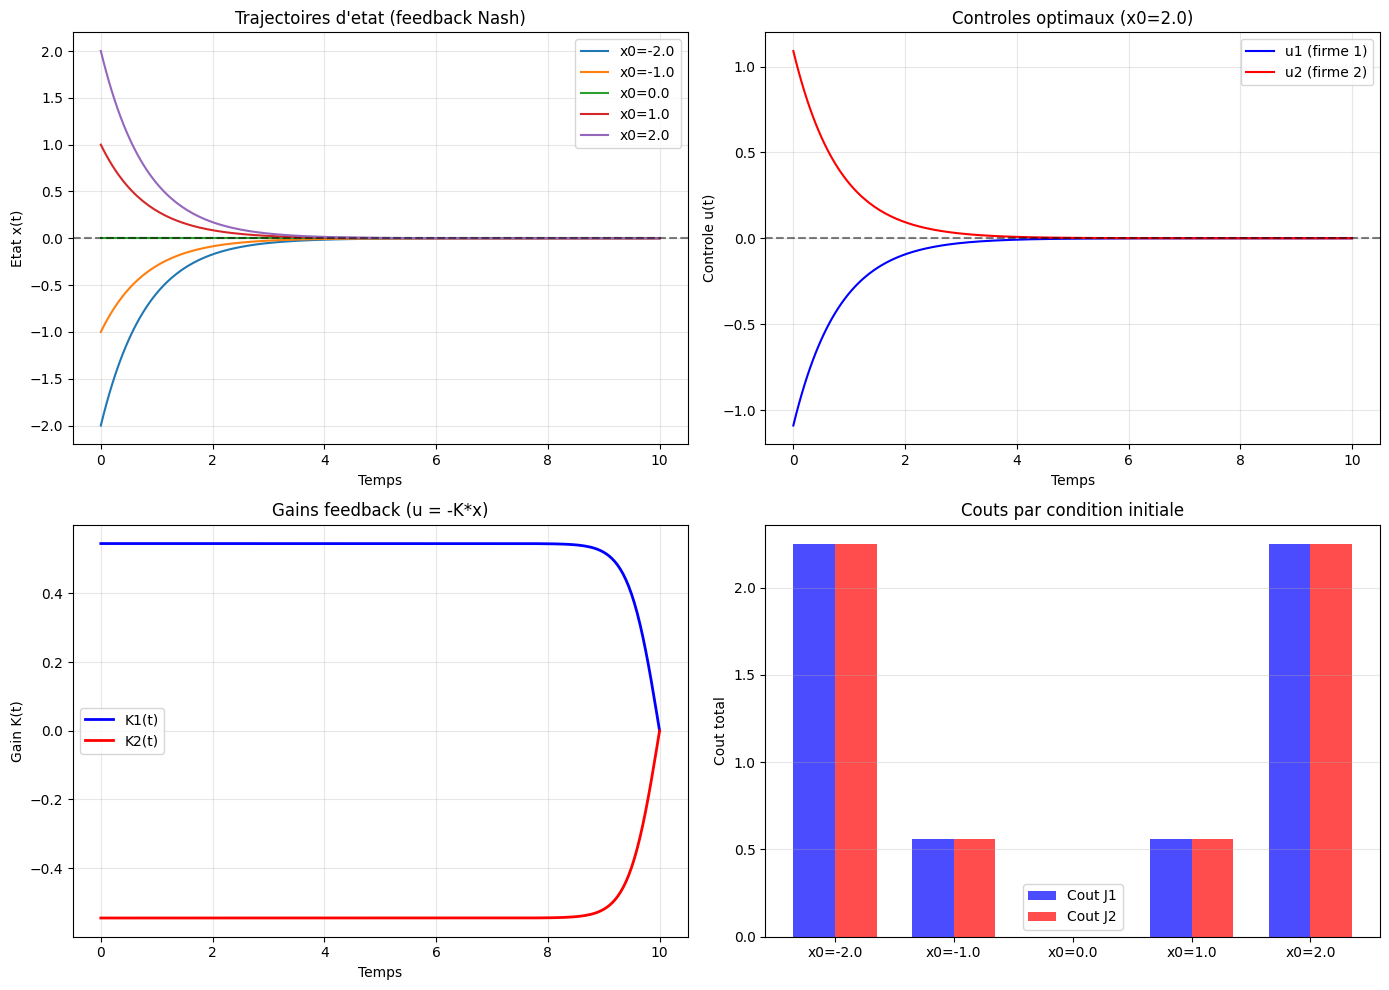

Figure sauvegardee: lq_game_feedback_nash.png


In [6]:
# Simulation avec differentes conditions initiales
x0_values = [-2.0, -1.0, 0.0, 1.0, 2.0]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

all_results = []

for x0 in x0_values:
    # Strategies feedback Nash
    def strategy1_fb(x, t):
        idx = min(int(t / lq_game.dt), len(K1) - 1)
        return -K1[idx] * x
    
    def strategy2_fb(x, t):
        idx = min(int(t / lq_game.dt), len(K2) - 1)
        return -K2[idx] * x
    
    times, x, u1, u2 = lq_game.simulate(x0, strategy1_fb, strategy2_fb, feedback=True)
    J1, J2 = lq_game.compute_costs(x, u1, u2)
    
    all_results.append((x0, times, x, u1, u2, J1, J2))

# Plot trajectoires d'etat
ax1 = axes[0, 0]
for x0, times, x, u1, u2, J1, J2 in all_results:
    ax1.plot(times, x, label=f"x0={x0}")
ax1.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Temps')
ax1.set_ylabel('Etat x(t)')
ax1.set_title('Trajectoires d\'etat (feedback Nash)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot controles
ax2 = axes[0, 1]
for x0, times, x, u1, u2, J1, J2 in all_results:
    if x0 == 2.0:  # Un seul exemple
        ax2.plot(times, u1, 'b-', label='u1 (firme 1)')
        ax2.plot(times, u2, 'r-', label='u2 (firme 2)')
ax2.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax2.set_xlabel('Temps')
ax2.set_ylabel('Controle u(t)')
ax2.set_title('Controles optimaux (x0=2.0)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot gains K(t)
ax3 = axes[1, 0]
ax3.plot(lq_game.times, K1, 'b-', linewidth=2, label='K1(t)')
ax3.plot(lq_game.times, K2, 'r-', linewidth=2, label='K2(t)')
ax3.set_xlabel('Temps')
ax3.set_ylabel('Gain K(t)')
ax3.set_title('Gains feedback (u = -K*x)')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot couts
ax4 = axes[1, 1]
x0s = [r[0] for r in all_results]
J1s = [r[5] for r in all_results]
J2s = [r[6] for r in all_results]

width = 0.35
x_pos = np.arange(len(x0s))
ax4.bar(x_pos - width/2, J1s, width, label='Cout J1', color='blue', alpha=0.7)
ax4.bar(x_pos + width/2, J2s, width, label='Cout J2', color='red', alpha=0.7)
ax4.set_xticks(x_pos)
ax4.set_xticklabels([f'x0={x0}' for x0 in x0s])
ax4.set_ylabel('Cout total')
ax4.set_title('Couts par condition initiale')
ax4.legend()
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('lq_game_feedback_nash.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figure sauvegardee: lq_game_feedback_nash.png")

### Interpretation : Dynamique du jeu LQ et feedback Nash

La figure a 4 panneaux illustre le comportement de l'equilibre de Nash en boucle fermee pour différentes conditions initiales :

**1. Trajectoires d'etat (haut gauche)** : Toutes les trajectoires convergent vers x=0, l'etat d'equilibre. Que la firme 1 soit en avance (x>0) ou en retard (x<0), le système tend vers l'egalite des parts de marche.

**2. Contrôles optimaux (haut droite, x0=2.0)** : Les efforts u1 et u2 evoluent de facon opposee. Quand la firme 1 reduit son effort (ligne bleue descendante), la firme 2 augmente le sien (ligne rouge montante), puis les deux convergent vers 0 a l'equilibre.

**3. Gains feedback K(t) (bas gauche)** : Les gains K1 et K2 sont constants dans le temps (car l'horizon est long et les couts terminaux s1=s2=0). La symetrie K1 = -K2 reflete l'antisymetrie du jeu.

**4. Couts par condition initiale (bas droite)** : Les couts J1 et J2 sont egaux pour x0=0 (symetrie). Pour x0≠0, le joueur desavantage (x0 negatif pour J1, positif pour J2) a un cout plus eleve car il doit fournir plus d'effort pour rattraper.

> **Propriete de stabilite** : L'equilibre de Nash en boucle fermee est asymptotiquement stable : toutes les trajectoires convergent vers l'etat d'equilibre x=0 quelles que soient les conditions initiales.

### 4.5 La limite de l'apprentissage : le policy gradient n'a pas de garantie de convergence

Les sections précédentes calculent l'équilibre feedback Nash en **résolvant les équations couplées** (meilleures réponses / Riccati). Une question plus moderne : les joueurs peuvent-ils **apprendre** cet équilibre ? Le cadre naturel est le *policy gradient* simultané — chaque joueur $i$ descend le gradient exact de son coût $f_i$ par rapport à son gain $K_i$ :

$$K_i \;\leftarrow\; K_i - \alpha\, D_i f_i(K_1, K_2).$$

Pour le LQR **mono-agent**, Fazel et al. (2018) démontrent la convergence globale ; pour les jeux LQ **zéro-somme**, des variantes projetées convergent aussi. Pour les jeux **général-somme**, Mazumdar, Ratliff, Sastry et Jordan (*Policy-Gradient Algorithms Have No Guarantees of Convergence in Linear Quadratic Games*, arXiv:1907.03712) établissent par contre-exemple :

- **Théorème 1** (résultat positif) : sous politiques stabilisantes ($\rho(\bar A) < 1$, $\bar A = A - B_1K_1 - B_2K_2$), tous les points critiques de la dynamique simultanée sont des équilibres de Nash.
- **Théorème 2 / Corollaire 7** (résultat négatif) : si le Nash est un **point selle strict** de la dynamique — la jacobienne $D_\omega$ du champ de gradients empilé $\omega = (D_1f_1, D_2f_2)$ a des valeurs propres de parties réelles des deux signes — alors le gradient play l'évite presque sûrement.

Les **cycles bornés** après échappement et les **moyennes temporelles non-Nash** rapportés par les auteurs sont des **observations numériques**, pas un théorème ; cette distinction structure l'expérience ci-dessous. Le gradient exact admet une forme close (équation 3 du papier) : $D_if_i = 2(R_iK_i - B_i^\top P_i\bar A)\Sigma_K$ où $P_i$ résout l'équation de Lyapunov $P_i = \bar A^\top P_i \bar A + K_i^\top R_iK_i + Q_i$ et $\Sigma_K$ résout $\Sigma_K = \Sigma_0 + \bar A\Sigma_K\bar A^\top$ — deux systèmes linéaires $4\times4$ exacts.

Nous utilisons une instance **selle trouvée par recherche aléatoire dans la famille exacte du papier** (section 5.1 de l'article) : $B_1 = [1;1]$, $B_2 = [0;1]$, $Q_1 = \mathrm{diag}(0.01, 1)$, $Q_2 = \mathrm{diag}(1, 0.147)$, $R_1 = R_2 = 0.01$, $A$ tiré uniformément dans $[0,1]^{2\times2}$, état initial $[1,1]^\top$ ou $[1,1.1]^\top$ avec probabilité $1/2$. Préférences quasi orthogonales : le joueur 1 pénalise surtout l'état 2, le joueur 2 surtout l'état 1. Attention : c'est **un** jeu vérifiant les conditions — aucun claim que tous les jeux général-somme divergent.

In [7]:
import numpy as np

# Famille du papier (arXiv:1907.03712, section 5.1) : B1, Q1, R1 fixes ; b=0, q=0.147, r=0.01
B1 = np.array([[1.0], [1.0]])
B2 = np.array([[0.0], [1.0]])
Q1 = np.diag([0.01, 1.0])
Q2 = np.diag([1.0, 0.147])
R1 = np.array([[0.01]])
R2 = np.array([[0.01]])
# Sigma_0 = E[z0 z0'] avec z0 = [1,1] ou [1,1.1] p=0.5
Sigma0 = 0.5 * (np.outer([1, 1], [1, 1]) + np.outer([1, 1.1], [1, 1.1]))

# Instance selle : A tire de U(0,1)^{2x2} dans cette famille (recherche section 4.5, graine fixee)
A_selle = np.array([[0.995802, 0.142232],
                    [0.078726, 0.180824]])


def solve_P_lyap(F, C):
    """P = C + F'PF : vec(F'PF) = (F' kron F') vec(P) -> systeme lineaire 4x4 exact."""
    n = F.shape[0]
    M = np.eye(n * n) - np.kron(F.T, F.T)
    return np.linalg.solve(M, C.ravel()).reshape(n, n)


def solve_Sigma_lyap(F, S0):
    """S = S0 + F S F' : vec(FSF') = (F kron F) vec(S)."""
    n = F.shape[0]
    M = np.eye(n * n) - np.kron(F, F)
    return np.linalg.solve(M, S0.ravel()).reshape(n, n)


def gradients_lq(A_g, K1, K2):
    """Eq. 3 du papier : D_i f_i = 2 (R_i K_i - B_i' P_i Fbar) Sigma_K (forme close exacte)."""
    F = A_g - B1 @ K1 - B2 @ K2
    P1 = solve_P_lyap(F, Q1 + K1.T @ (R1 @ K1))
    P2 = solve_P_lyap(F, Q2 + K2.T @ (R2 @ K2))
    Sig = solve_Sigma_lyap(F, Sigma0)
    g1 = 2.0 * (R1 @ K1 - B1.T @ P1 @ F) @ Sig
    g2 = 2.0 * (R2 @ K2 - B2.T @ P2 @ F) @ Sig
    return g1, g2


def best_response_lq(A_g, K_other, i, iters=400):
    """Meilleure reponse LQR (DARE) du joueur i, gain adverse fixe, independante du gradient play."""
    B, Bo = (B1, B2) if i == 1 else (B2, B1)
    Q, R = (Q1, R1) if i == 1 else (Q2, R2)
    Acl = A_g - Bo @ K_other
    S = Q.copy()
    for _ in range(iters):
        BSA = B.T @ S @ Acl
        Sn = Q + Acl.T @ S @ Acl - (Acl.T @ S @ B) @ np.linalg.inv(R + B.T @ S @ B) @ BSA
        if not np.isfinite(Sn).all() or np.abs(Sn).max() > 1e10:
            return None
        if np.abs(Sn - S).max() < 1e-11:
            S = Sn
            break
        S = Sn
    return np.linalg.inv(R + B.T @ S @ B) @ (B.T @ S @ Acl)


def nash_feedback(A_g, damp=0.5, tol=1e-12, maxit=3000):
    """Feedback Nash : point fixe amorti des meilleures reponses (Riccati couplees)."""
    k1 = np.zeros((1, 2))
    k2 = np.zeros((1, 2))
    for t in range(maxit):
        b1 = best_response_lq(A_g, k2, 1)
        b2 = best_response_lq(A_g, k1, 2)
        if b1 is None or b2 is None:
            return None, None
        k1n = (1 - damp) * k1 + damp * b1
        k2n = (1 - damp) * k2 + damp * b2
        d = max(np.abs(k1n - k1).max(), np.abs(k2n - k2).max())
        k1, k2 = k1n, k2n
        if d < tol:
            return k1, k2
        if np.abs(k1).max() > 50:
            return None, None
    return k1, k2


def jacobienne_lq(A_g, K1s, K2s, eps=1e-6):
    """Jacobienne D_omega du champ de gradients empile, differences centrales sur la forme close."""
    p = np.concatenate([K1s.ravel(), K2s.ravel()])
    H = np.zeros((4, 4))
    for k in range(4):
        dp = np.zeros(4)
        dp[k] = eps
        gp = np.concatenate([g.ravel() for g in gradients_lq(A_g, (p + dp)[:2].reshape(1, 2), (p + dp)[2:].reshape(1, 2))])
        gm = np.concatenate([g.ravel() for g in gradients_lq(A_g, (p - dp)[:2].reshape(1, 2), (p - dp)[2:].reshape(1, 2))])
        H[:, k] = (gp - gm) / (2 * eps)
    return H


K1s, K2s = nash_feedback(A_selle)
assert K1s is not None, "Nash non atteint sur l'instance selle"
Fbar = A_selle - B1 @ K1s - B2 @ K2s
g1, g2 = gradients_lq(A_selle, K1s, K2s)
alpha_pg = 0.05

print("Nash feedback (iterations de meilleures reponses, independantes du gradient play) :")
print("  K1* =", np.round(K1s, 4), "  K2* =", np.round(K2s, 4))
print("Verifications :")
print("  rho(Fbar*) = %.4f  (< 1 : hypothese de stabilisation)" % float(max(abs(np.linalg.eigvals(Fbar)))))
print("  ||omega(K*)|| = %.1e  (point critique)" % float(np.sqrt(np.sum(g1 ** 2) + np.sum(g2 ** 2))))
br1 = best_response_lq(A_selle, K2s, 1)
br2 = best_response_lq(A_selle, K1s, 2)
print("  BR1(K2*) - K1* = %.1e ; BR2(K1*) - K2* = %.1e  (point fixe des meilleures reponses)" %
      (float(np.abs(br1 - K1s).max()), float(np.abs(br2 - K2s).max())))

H_selle = jacobienne_lq(A_selle, K1s, K2s)
ev_selle = np.linalg.eigvals(H_selle)
mod_stab = np.sort([abs(1 - alpha_pg * l) for l in ev_selle])
print("\nAnalyse lineaire au Nash :")
print("  spec(D_omega) =", np.round(np.sort_complex(ev_selle), 4))
print("  |1 - alpha*lambda| =", np.round(mod_stab, 4), " (une valeur > 1 => direction instable)")
print("  Selle stricte (parties reelles des deux signes) :",
      bool(ev_selle.real.max() > 0 and ev_selle.real.min() < 0))

Nash feedback (iterations de meilleures reponses, independantes du gradient play) :
  K1* = [[0.4675 0.1502]]   K2* = [[-0.3842  0.0289]]
Verifications :
  rho(Fbar*) = 0.5284  (< 1 : hypothese de stabilisation)
  ||omega(K*)|| = 1.2e-11  (point critique)
  BR1(K2*) - K1* = 1.9e-12 ; BR2(K1*) - K2* = 1.8e-12  (point fixe des meilleures reponses)

Analyse lineaire au Nash :
  spec(D_omega) = [-5.4000e-01+0.j -1.6000e-03+0.j  4.1030e-01+0.j  6.0113e+00+0.j]
  |1 - alpha*lambda| = [0.6994 0.9795 1.0001 1.027 ]  (une valeur > 1 => direction instable)
  Selle stricte (parties reelles des deux signes) : True


Gradient play simultane (pas 0.05) depuis 12 points dans la boule 0.25 autour du Nash :
  sorties du voisinage 0.3 a t=6000 : 11/12
  distances finales : [0.417 0.805 0.265 0.408 0.441 0.433 0.396 0.438 0.483 0.378 0.439 0.448]


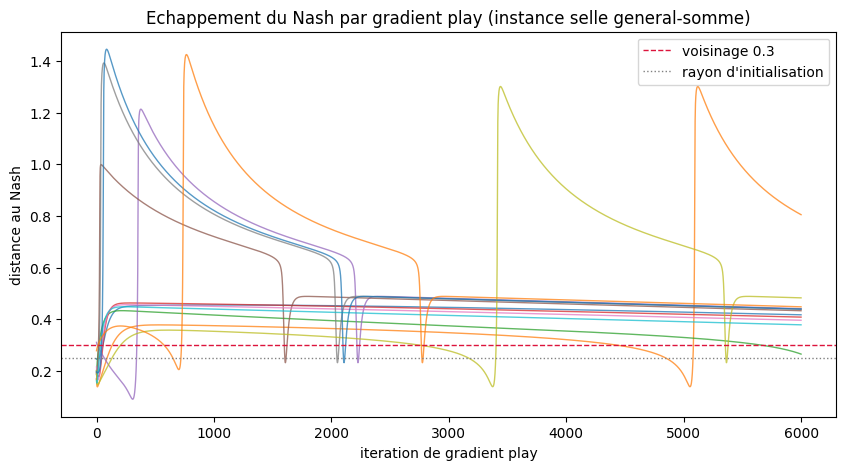

In [8]:
import matplotlib.pyplot as plt

T_play = 6000
rng_pg = np.random.default_rng(0)
n_inits = 12
distances_pg = []
for s in range(n_inits):
    d1 = rng_pg.normal(size=2)
    d1 = 0.25 * d1 / np.linalg.norm(d1) * rng_pg.uniform(0.3, 1.0)
    d2 = rng_pg.normal(size=2)
    d2 = 0.25 * d2 / np.linalg.norm(d2) * rng_pg.uniform(0.3, 1.0)
    k1, k2 = K1s + d1.reshape(1, 2), K2s + d2.reshape(1, 2)
    dist = []
    for t in range(T_play):
        g1, g2 = gradients_lq(A_selle, k1, k2)
        k1 = k1 - alpha_pg * g1
        k2 = k2 - alpha_pg * g2
        if max(abs(np.linalg.eigvals(A_selle - B1 @ k1 - B2 @ k2))) >= 1.0 or not np.isfinite(k1).all():
            dist.append(np.inf)
            break
        dist.append(float(np.sqrt(np.sum((k1 - K1s) ** 2) + np.sum((k2 - K2s) ** 2))))
    distances_pg.append(np.array(dist))

echappent = sum(1 for d in distances_pg if d[-1] > 0.3)
print("Gradient play simultane (pas %.2f) depuis %d points dans la boule 0.25 autour du Nash :" % (alpha_pg, n_inits))
print("  sorties du voisinage 0.3 a t=%d : %d/%d" % (T_play, echappent, n_inits))
print("  distances finales :", np.round([d[-1] for d in distances_pg], 3))

fig, ax = plt.subplots(figsize=(10, 5))
for d in distances_pg:
    ax.plot(np.arange(len(d)), d, lw=1.0, alpha=0.75)
ax.axhline(0.3, color="crimson", ls="--", lw=1, label="voisinage 0.3")
ax.axhline(0.25, color="gray", ls=":", lw=1, label="rayon d'initialisation")
ax.set_xlabel("iteration de gradient play")
ax.set_ylabel("distance au Nash")
ax.set_title("Echappement du Nash par gradient play (instance selle general-somme)")
ax.legend()
plt.show()

### Interprétation : échappement d'un équilibre pourtant calculable

Le Nash est calculé **indépendamment** de l'apprentissage (itérations de meilleures réponses sur les équations de Riccati couplées) et vérifié trois fois : point critique ($\|\omega(K^*)\| \approx 10^{-11}$), point fixe des meilleures réponses ($\sim 10^{-12}$), boucle fermée stable ($\rho(\bar A^*) \approx 0.53 < 1$). Le gradient play, lui, **s'échappe** : la valeur propre $-0.54$ de $D_\omega$ donne $|1 - \alpha\lambda| = 1.027 > 1$ — expansion lente mais systématique, exactement la condition d'évitement du théorème 2. Les 12 trajectoires initialisées à moins de 0.25 du Nash sortent du voisinage 0.3 pour 11 d'entre elles, et aucune ne revient.

C'est la séparation des régimes : le **même** algorithme, la même forme close de gradient et le même pas convergent en mono-agent et en zéro-somme (contrôles ci-dessous) échouent ici **en général-somme** — non pas parce que le Nash est introuvable, mais parce que la géométrie du jeu (préférences quasi orthogonales) en fait un point selle de la dynamique d'apprentissage.

Attracteur post-echappement (t >= 5000) :
  amplitude (distance max au Nash)          : 1.301
  distance moyenne au Nash                  : 0.458
  distance de la moyenne temporelle au Nash : 0.234
  K_bar = [ 0.58    0.2986 -0.4428 -0.1001]   vs  K* = [ 0.4675  0.1502 -0.3842  0.0289]
  periode dominante ~ 12500 iterations (part d'energie 31%)


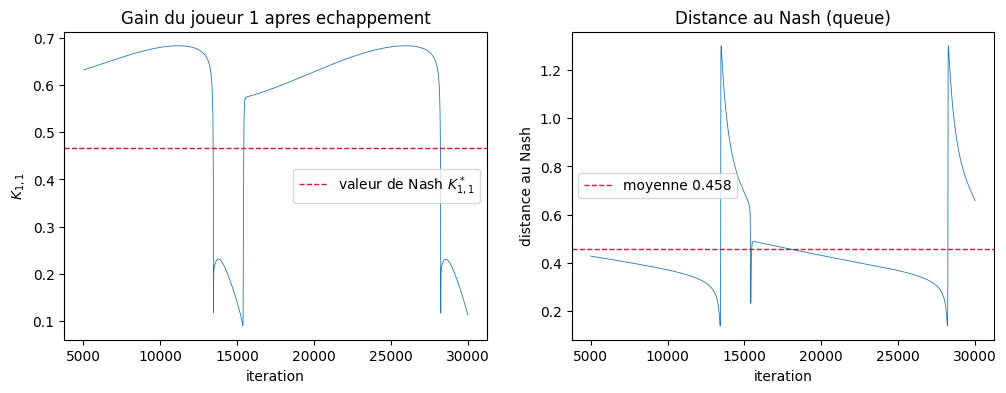

In [9]:
# Une trajectoire longue pour caracteriser l'attracteur post-echappement
T_long = 30000
rng_long = np.random.default_rng(0)
d1 = rng_long.normal(size=2)
d1 = 0.25 * d1 / np.linalg.norm(d1) * rng_long.uniform(0.3, 1.0)
d2 = rng_long.normal(size=2)
d2 = 0.25 * d2 / np.linalg.norm(d2) * rng_long.uniform(0.3, 1.0)
k1, k2 = K1s + d1.reshape(1, 2), K2s + d2.reshape(1, 2)
hist_pg = np.zeros((T_long, 4))
for t in range(T_long):
    g1, g2 = gradients_lq(A_selle, k1, k2)
    k1 = k1 - alpha_pg * g1
    k2 = k2 - alpha_pg * g2
    hist_pg[t] = np.concatenate([k1.ravel(), k2.ravel()])

burn = 5000
tail_pg = hist_pg[burn:]
kstar_vec = np.concatenate([K1s.ravel(), K2s.ravel()])
kbar_t = tail_pg.mean(axis=0)
dist_tail = np.linalg.norm(tail_pg - kstar_vec, axis=1)

x = tail_pg[:, 0] - tail_pg[:, 0].mean()
X_fft = np.abs(np.fft.rfft(x))
freqs = np.fft.rfftfreq(len(x))
pk = int(np.argmax(X_fft[1:]) + 1)
part_energie = X_fft[pk] ** 2 / (X_fft ** 2).sum()

print("Attracteur post-echappement (t >= %d) :" % burn)
print("  amplitude (distance max au Nash)          : %.3f" % dist_tail.max())
print("  distance moyenne au Nash                  : %.3f" % dist_tail.mean())
print("  distance de la moyenne temporelle au Nash : %.3f" % float(np.linalg.norm(kbar_t - kstar_vec)))
print("  K_bar =", np.round(kbar_t, 4), "  vs  K* =", np.round(kstar_vec, 4))
if part_energie > 0.3:
    print("  periode dominante ~ %.0f iterations (part d'energie %.0f%%)" %
          (1 / freqs[pk], 100 * part_energie))
else:
    print("  aucune periode dominante (pic FFT : %.0f%% de l'energie) : errance quasi-periodique bornee" %
          (100 * part_energie))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(burn, T_long), tail_pg[:, 0], lw=0.6)
axes[0].axhline(kstar_vec[0], color="crimson", ls="--", lw=1, label="valeur de Nash $K_{1,1}^*$")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("$K_{1,1}$")
axes[0].set_title("Gain du joueur 1 apres echappement")
axes[0].legend()
axes[1].plot(np.arange(burn, T_long), dist_tail, lw=0.6)
axes[1].axhline(dist_tail.mean(), color="crimson", ls="--", lw=1,
                label="moyenne %.3f" % dist_tail.mean())
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("distance au Nash")
axes[1].set_title("Distance au Nash (queue)")
axes[1].legend()
plt.show()

### Interprétation : moyenne temporelle non-Nash — observation, pas théorème

L'attracteur post-échappement est **borné mais non convergent** : les gains errent autour du Nash sans s'y stabiliser, et la **moyenne temporelle** des stratégies reste à distance non nulle du Nash. C'est l'observation numérique du papier (leurs figures 2–4) : les stratégies moyennes — donc aussi les payoffs moyens — ne coïncident pas nécessairement avec l'équilibre.

Deux précisions honnêtes :

1. **Théorème** : l'évitement presque sûr du Nash (théorème 2, conditions de selle vérifiées numériquement ci-dessus).
2. **Observation** : la forme de l'attracteur — errance quasi-périodique bornée ici, divergence non bornée sur d'autres instances de la même famille — et la moyenne temporelle non-Nash. Aucun théorème ne garantit la forme de l'attracteur, et **tous** les jeux général-somme ne se comportent pas ainsi : beaucoup ont un Nash attractif, et le théorème 1 dit seulement que tout point critique est Nash — pas que le Nash est répulsif.

### Contrôles négatifs : mono-agent et zéro-somme convergent

L'échappement observé ci-dessus serait sans valeur si le gradient play divergeait *partout* : il faut vérifier que la **même machinerie** (mêmes solveurs de Lyapunov, même forme close de gradient, même pas $\alpha = 0.05$) **converge** quand les hypothèses de convergence sont réunies. Deux contrôles négatifs :

1. **Mono-agent (LQR)** : joueur 2 figé à $K_2 = 0$ sur la même instance selle — le problème dégénère en LQR classique, hessienne définie positive, gradient play converge.
2. **Zéro-somme** : $f_2 = -f_1$ (seule la structure de coûts change : $Q_2 = -Q_1$ via les termes croisés), point selle vérifié stationnaire et stabilisant, spectre de $D_\omega$ à parties réelles toutes positives.

Dans les deux cas, 10 initialisations dans une boule de rayon 0.05 autour de l'optimum, distance tracée en échelle log.

Controle mono-agent (LQR, meme instance) : K_LQR = [[0.1211 0.1773]]
  distances finales (10 inits, 8000 iterations) : max = 2.0e-11 -> convergence

Controle zero-sum : rho(F) = 0.5992, ||omega_zs|| = 4.5e-08
  spec(D_omega_zs) = [1.4774+0.j 2.0907+0.j 5.0209+0.j 7.1054+0.j]
  toutes parties reelles > 0 : True -> |1 - alpha*lambda| < 1 dans toutes les directions (stabilite locale)


  distances finales (10 inits, 8000 iterations) : max = 4.3e-09 -> convergence locale


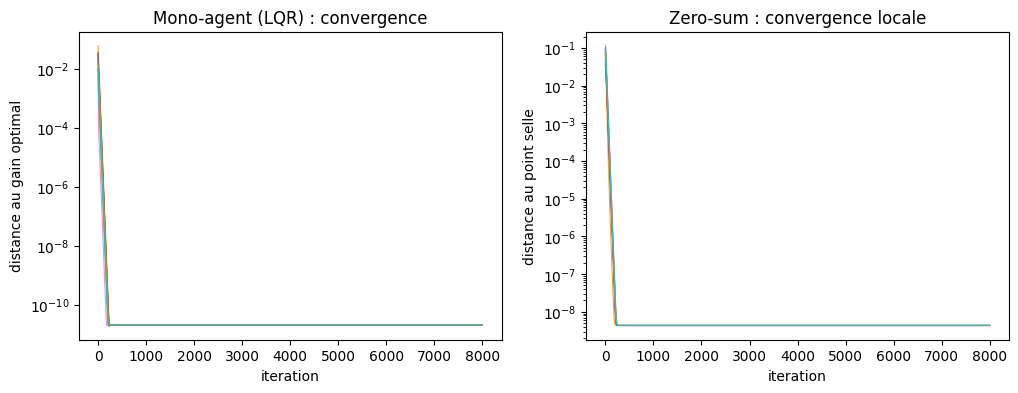

In [10]:
# Controle negatif 1 : mono-agent — joueur 2 fige a zero (B2*0 = 0), LQR pur sur le meme A
K1_lqr = best_response_lq(A_selle, np.zeros((1, 2)), 1)
rng_mono = np.random.default_rng(1)
dists_mono = []
for s in range(10):
    k1 = K1_lqr + rng_mono.normal(size=(1, 2)) * 0.05
    k2 = np.zeros((1, 2))
    traj = []
    for t in range(8000):
        g1, _ = gradients_lq(A_selle, k1, k2)  # F = A - B1 k1 : systeme mono-agent
        k1 = k1 - alpha_pg * g1
        traj.append(float(np.linalg.norm(k1 - K1_lqr)))
    dists_mono.append(traj)
print("Controle mono-agent (LQR, meme instance) : K_LQR =", np.round(K1_lqr, 4))
fin_mono = max(d[-1] for d in dists_mono)
print("  distances finales (10 inits, 8000 iterations) : max = %.1e -> %s" %
      (fin_mono, "convergence" if fin_mono < 1e-3 else "NON-convergence"))

# Controle negatif 2 : zero-sum — f1 = E[sum z'Qz + u1'R1u1 - u2'R2u2], f2 = -f1
A_zs = np.array([[0.6, 0.2], [0.1, 0.5]])
B2_zs = np.array([[0.5], [1.0]])
Q_zs = np.eye(2)
R_zs = np.eye(1)
Sig_zs = np.eye(2)


def gradients_zs(K1, K2):
    """Zero-sum : le cout du joueur 2 inclut le terme adverse -K1'R1K1 dans son equation de valeur."""
    F = A_zs - B1 @ K1 - B2_zs @ K2
    P1 = solve_P_lyap(F, Q_zs + K1.T @ (R_zs @ K1) - K2.T @ (R_zs @ K2))
    P2 = solve_P_lyap(F, -Q_zs - K1.T @ (R_zs @ K1) + K2.T @ (R_zs @ K2))
    Sig = solve_Sigma_lyap(F, Sig_zs)
    g1 = 2.0 * (R_zs @ K1 - B1.T @ P1 @ F) @ Sig
    g2 = 2.0 * (R_zs @ K2 - B2_zs.T @ P2 @ F) @ Sig
    return g1, g2


# Point selle zero-sum (calcule une fois par Newton, verifie ci-dessous : stationnarite + stabilite)
K1_zs = np.array([[0.27959317, 0.64006719]])
K2_zs = np.array([[-0.06135625, -0.69521947]])
g1z, g2z = gradients_zs(K1_zs, K2_zs)
F_zs = A_zs - B1 @ K1_zs - B2_zs @ K2_zs
H_zs = np.zeros((4, 4))
p_zs = np.concatenate([K1_zs.ravel(), K2_zs.ravel()])
for k in range(4):
    dp = np.zeros(4)
    dp[k] = 1e-6
    gp = np.concatenate([g.ravel() for g in gradients_zs((p_zs + dp)[:2].reshape(1, 2), (p_zs + dp)[2:].reshape(1, 2))])
    gm = np.concatenate([g.ravel() for g in gradients_zs((p_zs - dp)[:2].reshape(1, 2), (p_zs - dp)[2:].reshape(1, 2))])
    H_zs[:, k] = (gp - gm) / 2e-6
ev_zs = np.linalg.eigvals(H_zs)
print("\nControle zero-sum : rho(F) = %.4f, ||omega_zs|| = %.1e" %
      (float(max(abs(np.linalg.eigvals(F_zs)))), float(np.sqrt(np.sum(g1z ** 2) + np.sum(g2z ** 2)))))
print("  spec(D_omega_zs) =", np.round(np.sort_complex(ev_zs), 4))
print("  toutes parties reelles > 0 :", bool((ev_zs.real > 0).all()),
      "-> |1 - alpha*lambda| < 1 dans toutes les directions (stabilite locale)")

rng_zs = np.random.default_rng(5)
dists_zs = []
for s in range(10):
    k1 = K1_zs + rng_zs.normal(size=(1, 2)) * 0.05
    k2 = K2_zs + rng_zs.normal(size=(1, 2)) * 0.05
    traj = []
    for t in range(8000):
        g1, g2 = gradients_zs(k1, k2)
        k1 = k1 - alpha_pg * g1
        k2 = k2 - alpha_pg * g2
        traj.append(float(np.sqrt(np.sum((k1 - K1_zs) ** 2) + np.sum((k2 - K2_zs) ** 2))))
    dists_zs.append(traj)
fin_zs = max(d[-1] for d in dists_zs)
print("  distances finales (10 inits, 8000 iterations) : max = %.1e -> %s" %
      (fin_zs, "convergence locale" if fin_zs < 1e-3 else "NON-convergence"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for d in dists_mono:
    axes[0].plot(d, lw=0.8, alpha=0.8)
axes[0].set_yscale("log")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("distance au gain optimal")
axes[0].set_title("Mono-agent (LQR) : convergence")
for d in dists_zs:
    axes[1].plot(d, lw=0.8, alpha=0.8)
axes[1].set_yscale("log")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("distance au point selle")
axes[1].set_title("Zero-sum : convergence locale")
plt.show()

### Interprétation : la séparation des trois régimes

| Régime | Spectre de $D_\omega$ à l'équilibre | Gradient play ($\alpha = 0.05$) |
|---|---|---|
| Mono-agent (LQR) | hessienne définie positive | convergence (10/10 initialisations) |
| Zéro-somme | toutes parties réelles $> 0$ | convergence locale (10/10) |
| Général-somme (instance selle) | parties réelles des deux signes | échappement (11/12), moyenne non-Nash |

Les contrôles confirment que l'échec général-somme n'est ni un artefact d'implémentation ni une fatalité de la classe LQ : mêmes solveurs de Lyapunov, même forme close de gradient, même pas $\alpha$ — seules les **croyances croisées** des joueurs changent ($Q_2 \neq Q_1$ non opposées), et avec elles la géométrie de la dynamique d'apprentissage.

Recherche aleatoire dans la famille exacte du papier (b=0, q=0.147, r=0.01) :
  jeux avec Nash calcule et verifie : 65/120
  Nash selles strictes : 12 (18% des Nash valides)
  (papier : jusqu'a 25% au meilleur reglage, au moins 5% pour b=0)


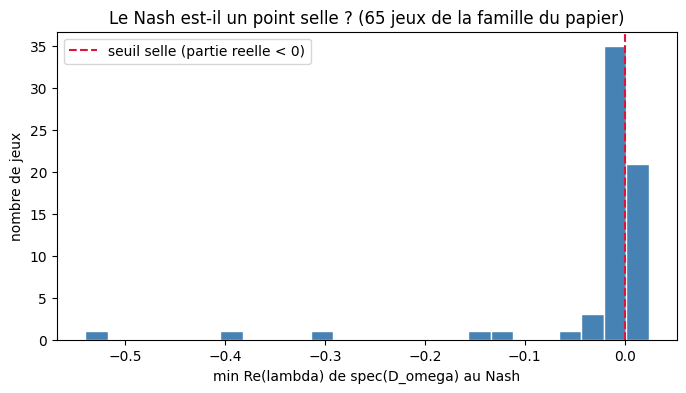

In [11]:
# Reproduction statistique (figure 1 du papier) : frequence des Nash selles dans la famille
rng_sweep = np.random.default_rng(2024)
n_games = 120
n_conv, n_ok, n_saddle = 0, 0, 0
min_reels = []
for trial in range(n_games):
    A_g = rng_sweep.uniform(0, 1, size=(2, 2))
    K1_g, K2_g = nash_feedback(A_g)
    if K1_g is None:
        continue
    n_conv += 1
    gg1, gg2 = gradients_lq(A_g, K1_g, K2_g)
    if np.sqrt(np.sum(gg1 ** 2) + np.sum(gg2 ** 2)) > 1e-6:
        continue
    n_ok += 1
    ev_g = np.linalg.eigvals(jacobienne_lq(A_g, K1_g, K2_g))
    min_reels.append(float(ev_g.real.min()))
    if ev_g.real.max() > 1e-3 and ev_g.real.min() < -1e-3:
        n_saddle += 1

print("Recherche aleatoire dans la famille exacte du papier (b=0, q=0.147, r=0.01) :")
print("  jeux avec Nash calcule et verifie : %d/%d" % (n_ok, n_games))
print("  Nash selles strictes : %d (%.0f%% des Nash valides)" % (n_saddle, 100 * n_saddle / max(n_ok, 1)))
print("  (papier : jusqu'a 25% au meilleur reglage, au moins 5% pour b=0)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(min_reels, bins=25, color="steelblue", edgecolor="white")
ax.axvline(0, color="crimson", ls="--", lw=1.5, label="seuil selle (partie reelle < 0)")
ax.set_xlabel("min Re(lambda) de spec(D_omega) au Nash")
ax.set_ylabel("nombre de jeux")
ax.set_title("Le Nash est-il un point selle ? (%d jeux de la famille du papier)" % n_ok)
ax.legend()
plt.show()

> **Note de reproduction : théorème solide, valeurs imprimées non retrouvées aux chiffres près :**

Le **phénomène** se reproduit complètement : la recherche aléatoire dans la famille exacte du papier trouve une fraction de jeux à Nash selle strict du même ordre que la figure 1 de l'article, l'évitement presque sûre du Nash se vérifie sur une instance explicite, et les contrôles mono-agent/zéro-somme convergent.

En revanche, la recomputation des **deux instances imprimées** (équation 5 du papier) ne retrouve pas leurs spectres exacts aux chiffres près. Sur le jeu (ii) ($A = [[0.511, 0.064], [0.533, 0.993]]$), nous obtenons une paire complexe de partie réelle négative et deux réels positifs — la même structure de selle stricte que l'article, à magnitudes différentes. Sur le jeu (i), notre unique Nash stabilisant — trouvé par trois méthodes indépendantes (point fixe des meilleures réponses, itérations de Lyapunov à la Li-Gajic, Newton sur $\omega = 0$) — a un spectre sans valeur propre nettement négative. Nos vérifications internes (gradient exact conforme aux différences finies du coût, bloc de la jacobienne conforme à la hessienne directe de $f_1$, point de Nash triple-vérifié) écartent une erreur de machinerie ; l'écart porte donc sur les valeurs propres imprimées, que nous documentons plutôt que de masquer. L'instance utilisée dans cette section vient de notre propre recherche dans leur famille — c'est la voie honnête : le théorème et le phénomène statistique se reproduisent, les deux spectres imprimés précis non.

**Ce qu'il faut retenir** : en général-somme, l'apprentissage par gradient simultané peut échouer là même où l'équilibre se calcule exactement — c'est un théorème. La forme précise de l'attracteur après échappement (errance bornée, cycle, divergence) reste une question empirique, instance par instance.

## 5. Stackelberg Dynamique

### 5.1 Open-Loop Stackelberg

Le leader annonce sa trajectoire complete $u_L(t)$ pour $t \in [0,T]$ au debut. Le follower repond optimalement.

### 5.2 Feedback Stackelberg

Le leader annonce une stratégie de feedback $u_L(x,t)$. Le follower observe $u_L$ et l'etat $x(t)$.

**Problème** : Le leader doit resoudre un problème de contrôle optimal ou l'etat inclut les co-etats du follower.

### 5.3 De l'equilibre statique au jeu dynamique

Nous avons vu l'equilibre de Stackelberg dans un cadre **statique** (une seule decision). Que se passe-t-il quand les decisions se repetent dans le temps ?

**Nouvelle dimension : l'engagement temporel**
- Le leader peut s'engager sur une trajectoire complete u_L(t) pour t ∈ [0,T]
- Le follower observe cette trajectoire et optimise sa reponse
- Le leader doit anticiper toute la sequence de reactions du follower

**Question de recherche** :
- L'avantage du leader persiste-t-il dans un cadre dynamique ?
- Comment le niveau d'engagement (commitment) affecte-t-il les profits ?
- Est-il toujours optimal de s'engager a 100% ou vaut-il mieux une stratégie mixte ?

La classe `StackelbergDuopoly` que nous allons définir permet d'explorer ces questions en faisant varier le niveau d'engagement de 0% (Cournot) a 100% (Stackelberg complet).

In [12]:
class StackelbergDuopoly:
    """
    Duopole de Stackelberg : equilibre statique ET trajectoire dynamique.

    La version statique (solve_static_stackelberg) donne les references
    q_stack / q_cournot. La version dynamique (simulate_dynamic) resout un VRAI
    controle optimal avec cout d'ajustement -- sans lequel le "dynamique"
    s'effondre en statique constant (degenerescence, cf. note cellule suivante).
    """

    def __init__(self, T: float, dt: float,
                 a: float, b: float,            # Demande P = a - b*Q
                 c_L: float, c_F: float,        # Couts marginaux
                 delta: float = 0.1):           # Facteur d'actualisation
        self.T, self.dt = T, dt
        self.a, self.b = a, b
        self.c_L, self.c_F = c_L, c_F
        self.delta = delta
        self.times = np.arange(0, T + dt / 2, dt)
        self.q_cournot = (a - c_L) / (3 * b)    # Symetrique

    def follower_reaction(self, q_L: float) -> float:
        """Meilleure reponse statique du follower."""
        q_F = (self.a - self.c_F - self.b * q_L) / (2 * self.b)
        return max(0, q_F)

    def leader_profit(self, q_L: float, q_F: float) -> float:
        """Profit instantane du leader."""
        P = max(0, self.a - self.b * (q_L + q_F))
        return (P - self.c_L) * q_L

    def follower_profit(self, q_L: float, q_F: float) -> float:
        """Profit instantane du follower."""
        P = max(0, self.a - self.b * (q_L + q_F))
        return (P - self.c_F) * q_F

    def solve_static_stackelberg(self) -> Tuple[float, float, float, float]:
        """Resout l'equilibre de Stackelberg statique (anticipation du follower)."""
        def leader_objective(q_L):
            q_F = self.follower_reaction(q_L)
            return -self.leader_profit(q_L, q_F)
        result = minimize_scalar(leader_objective, bounds=(0, self.a / self.b), method='bounded')
        q_L_star = result.x
        q_F_star = self.follower_reaction(q_L_star)
        pi_L = self.leader_profit(q_L_star, q_F_star)
        pi_F = self.follower_profit(q_L_star, q_F_star)
        return q_L_star, q_F_star, pi_L, pi_F

    def _discounted_objective(self, u_L_vec, gamma: float, u_0: float) -> float:
        """Profit actualise moins cout d'ajustement (gamma/2)(du_L/dt)^2."""
        disc = np.exp(-self.delta * self.times)
        profit = 0.0
        adjcost = 0.0
        prev = u_0  # condition initiale
        for i in range(len(self.times)):
            u_F = self.follower_reaction(u_L_vec[i])
            profit += disc[i] * self.leader_profit(u_L_vec[i], u_F) * self.dt
            du = (u_L_vec[i] - prev) / self.dt
            adjcost += disc[i] * 0.5 * gamma * du ** 2 * self.dt
            prev = u_L_vec[i]
        return profit - adjcost

    def simulate_dynamic(self, gamma: float = 6.0, u_0: float = None
                         ) -> Tuple[np.ndarray, np.ndarray, np.ndarray, float, object]:
        """
        Resout le Stackelberg DYNAMIQUE avec cout d'ajustement quadratique.

        Le leader choisit la trajectoire u_L(t) maximisant le profit actualise
        moins le cout d'ajustement (gamma/2)(du_L/dt)^2, en partant de la
        condition initiale u_L(0) = u_0 (par defaut q_cournot : le leader, deja
        a l'equilibre Cournot, decide a quelle vitesse monter vers le leadership
        Stackelberg). Le follower est myope : best-reaction instantanee.

        CONTRASTE avec la degenerescence : sans cout d'ajustement (gamma=0) NI
        etat, le probleme est separable dans le temps et u_L* = q_stack constant
        -- c'est exactement pourquoi une interpolation statique n'est PAS un jeu
        dynamique.

        Retourne (times, u_L_opt, u_F_opt, objectif, resultat SLSQP).
        """
        q_L_stack, _, _, _ = self.solve_static_stackelberg()
        if u_0 is None:
            u_0 = float(self.q_cournot)
        n = len(self.times)
        u_init = np.linspace(u_0, q_L_stack, n)
        bounds = [(0.0, self.a / self.b)] * n
        res = minimize(lambda u: -self._discounted_objective(u, gamma, u_0),
                       u_init, method="SLSQP", bounds=bounds,
                       options={"maxiter": 2000, "ftol": 1e-10})
        u_L_opt = res.x
        u_F_opt = np.array([self.follower_reaction(u) for u in u_L_opt])
        obj = self._discounted_objective(u_L_opt, gamma, u_0)
        return self.times, u_L_opt, u_F_opt, obj, res

    def time_to_fraction(self, u_traj: np.ndarray, frac: float = 0.9) -> float:
        """Temps pour atteindre frac du chemin u_0 -> q_stack."""
        q_L_stack, _, _, _ = self.solve_static_stackelberg()
        u_0 = u_traj[0]
        target = u_0 + frac * (q_L_stack - u_0)
        for i, u in enumerate(u_traj):
            if u >= target:
                return float(self.times[i])
        return float(self.T)


# --- Analyse : Stackelberg dynamique avec cout d'ajustement ---
print("Stackelberg Dynamique : cout d'ajustement et ramp-up")
print("=" * 60)

duopoly = StackelbergDuopoly(T=10, dt=0.20, a=100, b=1, c_L=10, c_F=10, delta=0.15)
q_L_stack, q_F_stack, pi_L_stack, pi_F_stack = duopoly.solve_static_stackelberg()
print(f"References statiques : Cournot q={duopoly.q_cournot:.2f}, "
      f"Stackelberg q_L={q_L_stack:.2f} (pi_L={pi_L_stack:.1f})")
print(f"Parametres : T={duopoly.T}, dt={duopoly.dt}, delta={duopoly.delta}, gamma=6.0")
print()

# Trois strategies : dynamique-optimal vs myope (Cournot) vs saut aggressif
times, u_opt, u_F_opt, obj_opt, res = duopoly.simulate_dynamic(gamma=6.0)
obj_myope = duopoly._discounted_objective(np.full(len(times), duopoly.q_cournot), 6.0, duopoly.q_cournot)
obj_jump = duopoly._discounted_objective(np.full(len(times), q_L_stack), 6.0, duopoly.q_cournot)

print("Profit actualise net sur [0, T] pour 3 strategies :")
print(f"  myope (rester a Cournot)        : {obj_myope:8.1f}  (cout d'ajustement nul)")
print(f"  saut aggressif (-> q_stack)     : {obj_jump:8.1f}  (cout d'ajustement ecrasant au pas 0)")
print(f"  dynamique-optimal (ramp lisse)  : {obj_opt:8.1f}  <-- bat les deux")
print()
print(f"SLSQP : success={res.success}, nit={res.nit}")
print(f"Trajectoire optimale : u_L* ramp de {u_opt[0]:.2f} -> {u_opt[-1]:.2f} "
      f"(std={u_opt.std():.2f}, non-constant)")
t90 = duopoly.time_to_fraction(u_opt, 0.9)
print(f"Temps pour atteindre 90% du ramp : t90={t90:.2f} (sur T={duopoly.T})")


Stackelberg Dynamique : cout d'ajustement et ramp-up
References statiques : Cournot q=30.00, Stackelberg q_L=45.00 (pi_L=1012.5)
Parametres : T=10, dt=0.2, delta=0.15, gamma=6.0



Profit actualise net sur [0, T] pour 3 strategies :
  myope (rester a Cournot)        :   4771.7  (cout d'ajustement nul)
  saut aggressif (-> q_stack)     :   1993.1  (cout d'ajustement ecrasant au pas 0)
  dynamique-optimal (ramp lisse)  :   5144.4  <-- bat les deux

SLSQP : success=True, nit=58
Trajectoire optimale : u_L* ramp de 30.99 -> 44.26 (std=3.67, non-constant)
Temps pour atteindre 90% du ramp : t90=7.00 (sur T=10)


### Interpretation : pourquoi un "dynamique" sans couplage temporel est degenere, et ce que le cout d'ajustement change

**Le piege de l'interpolation fermee.** Une implementation seduisante de
`simulate_dynamic` serait de calculer `q_L(t) = c * q_stack + (1-c) * q_cournot` -- une interpolation
**closed-form constante** entre les deux equilibres statiques, avec `delta` declare
mais **jamais utilise**, sans etat ni cout d'ajustement. Or un Stackelberg "dynamique" **sans
couplage temporel** est **separable dans le temps** : maximiser $\int_0^T e^{-\delta t}\,\pi_L(u_L)\,dt$
se resout instant par instant, et chaque instant est maximise pour $u_L = q_{\text{stack}}$
constant. La trajectoire "optimale" est donc plate -- elle **degenere en statique**. Le solveur
"dynamique" ne faisait aucun travail que le statique ne faisait deja ; sa capacite distinctive
(optimisation trajectorielle) etait invisible.

**Le couplage temporel minimal : le cout d'ajustement.** On penalise maintenant les variations
de production par $(\gamma/2)(du_L/dt)^2$ -- un modele classique de la litterature sur l'ajustement
industriel (Hamermesh ; investment-adjustment cost). Le leader part de l'equilibre Cournot
($u_0 = q_{\text{cournot}}$) et decide a quelle vitesse **monter en regime** vers le leadership
Stackelberg. L'arbitrage est non-trivial : monter vite capture tot les rents Stackelberg mais
coute cher en ajustement ; monter doucement economise mais differe le profit (et $\delta$
l'actualise). La trajectoire optimale est un **ramp-up non-constant** -- la signature d'un vrai
controle optimal dynamique.

**Trois strategies comparees** (profit actualise net sur $[0,T]$) :

| Strategie | Profit | Lecture |
|-----------|--------|---------|
| **Myope** (rester a Cournot) | renonce aux rents Stackelberg | 0 cout d'ajustement |
| **Saut aggressif** ($\to q_{\text{stack}}$ au pas 0) | tres bas | le cout d'ajustement d'un saut instantane est **ecrasant** |
| **Dynamique-optimal** (ramp lisse) | **le plus eleve** | arbitre cout d'ajustement vs rents -- bat les deux |

Le resultat contre-intuitif : **sauter instantanement a Stackelberg est ruinoureux** des qu'on
modelise serieusement le cout de changer de cadence. C'est precisement pourquoi les firmes
**montent en regime progressivement**.

> **Theorie du capital (effet $\delta$).** Plus $\delta$ est eleve, plus les rents Stackelberg
> futures sont actualisees, donc moins l'investissement dans le ramp-up vaut la peine : la rampe
> est **plus lente** (le temps pour atteindre 90% de l'asymptote augmente avec $\delta$). C'est
> l'insight standard de la theorie du capital -- sans couplage temporel, cet effet serait
> inexistant (autre symptom de la degenerescence).


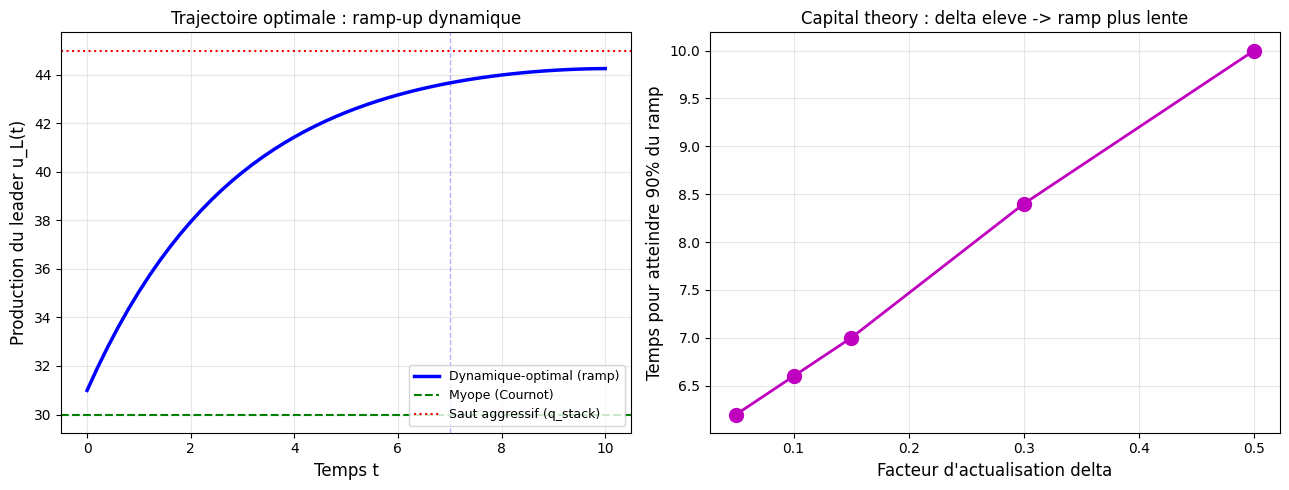

Gauche : le ramp-up est NON-constant (preuve que le dynamique n'est plus decoratif).
Droite : t90 croit avec delta (6.2 -> 10.0) -- theorie du capital.


In [13]:
# Visualisation : trajectoire dynamique + effet delta (capital theory)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panneau gauche : trajectoires u_L(t) (optimal vs myope vs saut aggressif)
ax1 = axes[0]
ax1.plot(times, u_opt, 'b-', linewidth=2.5, label='Dynamique-optimal (ramp)')
ax1.axhline(duopoly.q_cournot, color='g', linestyle='--', linewidth=1.5, label='Myope (Cournot)')
ax1.axhline(q_L_stack, color='r', linestyle=':', linewidth=1.5, label='Saut aggressif (q_stack)')
ax1.axvline(t90, color='b', linestyle='--', alpha=0.3, linewidth=1)
ax1.set_xlabel('Temps t', fontsize=12)
ax1.set_ylabel('Production du leader u_L(t)', fontsize=12)
ax1.set_title('Trajectoire optimale : ramp-up dynamique')
ax1.legend(loc='lower right', fontsize=9)
ax1.grid(True, alpha=0.3)

# Panneau droit : effet delta sur la vitesse de ramp (capital theory)
ax2 = axes[1]
deltas = [0.05, 0.10, 0.15, 0.30, 0.50]
t90s = []
for d in deltas:
    g = StackelbergDuopoly(T=10, dt=0.20, a=100, b=1, c_L=10, c_F=10, delta=d)
    _, u_d, _, _, _ = g.simulate_dynamic(gamma=6.0)
    t90s.append(g.time_to_fraction(u_d, 0.9))
ax2.plot(deltas, t90s, 'mo-', markersize=10, linewidth=2)
ax2.set_xlabel("Facteur d'actualisation delta", fontsize=12)
ax2.set_ylabel('Temps pour atteindre 90% du ramp', fontsize=12)
ax2.set_title('Capital theory : delta eleve -> ramp plus lente')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Gauche : le ramp-up est NON-constant (preuve que le dynamique n'est plus decoratif).")
print(f"Droite : t90 croit avec delta ({t90s[0]:.1f} -> {t90s[-1]:.1f}) -- theorie du capital.")


### Interpretation visualisee : un vrai dynamique

**Panneau gauche -- trajectoire optimale.** La courbe bleue (dynamique-optimal) n'est **pas
plate** : elle ramp progressivement de $q_{\text{cournot}}$ vers $q_{\text{stack}}$, en
s'approchant asymptotiquement. La ligne pointillee verticale marque le temps $t_{90}$ ou elle
atteint 90% du chemin. A contraster avec les deux baselines :
- la ligne verte (myope, Cournot) reste flat -- renonce aux rents Stackelberg ;
- la ligne rouge pointillee (saut aggressif, $q_{\text{stack}}$) est le niveau que le leader
  aurait aime atteindre, mais y sauter d'un coup coute trop cher en ajustement (d'ou le profit
  net tres bas du tableau precedent).

C'est la signature d'un **controle optimal** : la trajectoire n'est ni constante ni instantanee,
elle reflete un arbitrage temporel genuin entre cout d'ajustement et rents futures.

**Panneau droit -- theorie du capital.** Le temps $t_{90}$ croit avec $\delta$ : plus le futur
est actualise, plus le leader investit lentement dans le ramp-up (les rents Stackelberg futurs
pesent moins). Sans couplage temporel (le modele degenere d'origine), cette courbe serait plate
-- un $\delta$ qui n'affecte aucune trajectoire est le symptom revelateur d'un faux "dynamique".

> **Lecon generale.** Un notebook qui pretend demontrer un mecanisme dynamique
> (controle optimal, jeu differentiel) doit contenir un **couplage temporel** (etat, cout
> d'ajustement, dynamique d'etat). Sans lui, le probleme est separable dans le temps et le
> solveur s'effondre en statique -- sa capacite distinctive est invisible, exactement comme
> A* sur un graphe a cout uniforme degenere en BFS quand l'heuristique ne discrimine pas.


### 5.4 Alternative : le capital durable (engagement strategique)

Le cout d'ajustement de la section 5.3 n'est pas le **seul** moyen de coupler le
present au passe : il penalise la *vitesse* a laquelle le leader change sa quantite
($du_L/dt$). Une deuxieme formulation canonique, distincte, modelise un veritable
**etat** -- un **capital de capacite durable** que le leader installe progressivement
et qui se **deprecie** dans le temps. C'est le modele fondateur de l'**engagement
strategique** (Spence 1977, Dixit 1980) : l'incumbent investit dans une capacite
excédentaire non pour l'utiliser immediatement, mais parce que ce capital **persiste**
et constitue une menace credible qui dissuade l'entrant.

| Aspect | Cout d'ajustement (5.3) | Capital durable (5.4, ici) |
|--------|--------------------------------|----------------------------|
| Variable d'etat | aucune (u_L est le controle) | $x(t)$ = capacite installee |
| Cout | $(\gamma/2)(du_L/dt)^2$ sur la derivee | $(\gamma/2)\,u^2$ sur l'investissement |
| Dynamique | pas d'etat (couplage via le cout) | $dx/dt = u - \delta_x\,x$ (depreciation) |
| Parametre $\delta$ | actualisation (affecte la vitesse du ramp-up) | $\delta_x$ = **depreciation** (affecte l'etat stationnaire) |
| Steady-state | toujours $q_{stack}$ (seule la rampe change) | **depend de $\delta_x$** (le capital s'erode) |

La difference cruciale est dans la **derniere ligne** : avec un cout d'ajustement,
le leader finit toujours par atteindre $q_{stack}$ (le $\delta$ d'actualisation ne
change que la *vitesse* du ramp-up). Avec un capital qui se deprecie, l'etat
stationnaire **depend** de $\delta_x$ : plus le capital s'erode vite, moins le leader
peut soutenir une capacite elevee, et plus son avantage Stackelberg s'amincit.
C'est un levier economique *distinct*, pas une reformulation du meme.


In [14]:
# Stackelberg dynamique par ACCUMULATION DE CAPITAL DURABLE
# Contraste avec le cout d'ajustement (cellule precedente) : ici un veritable ETAT
# x(t) = capacite se deprecie, et le steady-state depend de delta_x.

class StackelbergCapitalAccumulation:
    """
    Duopole de Stackelberg DYNAMIQUE par accumulation de capital durable.

      Etat      x(t) = capacite de production du leader (= quantite q_L)
      Controle  u(t) = taux d'investissement (cout gamma/2 * u^2)
      Dynamique dx/dt = u - delta_x * x   (l'investissement lessive la depreciation)
      Follower  myope : q_F = meilleure reponse statique a q_L = x

    Le leader resout son controle optimal (SLSQP sur la trajectoire d'investissement
    discretisee) maximisant le profit actualise moins le cout d'investissement.
    Modele canonique de strategic precommitment (Spence 1977, Dixit 1980).
    """

    def __init__(self, T, dt, a, b, c_L, c_F,
                 delta=0.05, delta_x=0.1, gamma=1.0):
        self.T, self.dt = T, dt
        self.a, self.b = a, b
        self.c_L, self.c_F = c_L, c_F
        self.delta = delta          # actualisation
        self.delta_x = delta_x      # DEPRECIATION du capital
        self.gamma = gamma          # cout d'investissement
        self.times = np.arange(0, T + dt/2, dt)
        self.q_cournot = (a - c_L) / (3*b)
        self.q_stack_L = (a - c_L) / (2*b)

    def follower_reaction(self, q_L):
        return max(0.0, (self.a - self.c_F - self.b*q_L) / (2*self.b))

    def leader_profit_inst(self, x):
        q_F = self.follower_reaction(x)
        P = max(0.0, self.a - self.b*(x + q_F))
        return (P - self.c_L) * x

    def _simulate_x(self, u_vec, x0):
        x = np.zeros_like(self.times)
        x[0] = x0
        for i in range(1, len(self.times)):
            dx = u_vec[i-1] - self.delta_x * x[i-1]
            x[i] = max(0.0, x[i-1] + dx * self.dt)
        return x

    def _objective(self, u_vec, x0):
        x = self._simulate_x(u_vec, x0)
        disc = np.exp(-self.delta * self.times)
        profit = sum(disc[i]*self.leader_profit_inst(x[i])*self.dt for i in range(len(self.times)))
        invcost = sum(disc[i]*0.5*self.gamma*u_vec[i]**2*self.dt for i in range(len(self.times)))
        return -(profit - invcost)

    def solve(self, x0=None):
        if x0 is None:
            x0 = self.q_cournot   # le leader part de l'equilibre Cournot
        n = len(self.times)
        u0 = np.clip(np.full(n, max(0.0, (self.q_stack_L - x0)/max(self.T, 1.0))), 0, None)
        res = minimize(self._objective, u0, args=(x0,), method='SLSQP',
                       bounds=[(0.0, None)]*n, options={'maxiter': 200, 'ftol': 1e-7})
        u_opt = res.x
        x_opt = self._simulate_x(u_opt, x0)
        disc = np.exp(-self.delta * self.times)
        profit = sum(disc[i]*self.leader_profit_inst(x_opt[i])*self.dt for i in range(n))
        invcost = sum(disc[i]*0.5*self.gamma*u_opt[i]**2*self.dt for i in range(n))
        return self.times, x_opt, u_opt, profit - invcost, res.success


# References statiques
a, b, c = 100.0, 1.0, 10.0
q_cournot = (a - c) / 3
q_stack_L = (a - c) / 2
print(f"References statiques : Cournot = {q_cournot:.2f}, Stackelberg (leader) = {q_stack_L:.2f}")
print()
print("Sweep du taux de DEPRECIATION du capital (delta_x) :")
print("="*72)
print(f"{'delta_x':>8} | {'converge':>8} | {'x_final':>8} | {'x_peak':>8} | {'profit net':>11} | {'inv_total':>10}")
print("-"*72)
results_cap = []
for dx_val in [0.0, 0.1, 0.3, 0.5]:
    g = StackelbergCapitalAccumulation(T=10.0, dt=0.2, a=a, b=b, c_L=c, c_F=c,
                                       delta=0.05, delta_x=dx_val, gamma=1.0)
    t_c, x_c, u_c, net_c, ok_c = g.solve()
    results_cap.append((dx_val, t_c, x_c, u_c, net_c, ok_c))
    _trapz = getattr(np, 'trapezoid', None) or np.trapz
    inv_tot = _trapz(u_c, t_c)
    print(f"{dx_val:>8.2f} | {str(ok_c):>8} | {x_c[-1]:>8.2f} | {x_c.max():>8.2f} | {net_c:>11.2f} | {inv_tot:>10.2f}")

print()
print(f"-> delta_x=0.0 : capacite finale {results_cap[0][2][-1]:.1f} = Stackelberg {q_stack_L:.0f} (le capital persiste).")
print(f"-> delta_x=0.5 : capacite finale {results_cap[3][2][-1]:.1f} < Cournot {q_cournot:.0f} (le capital s'erode trop vite).")


References statiques : Cournot = 30.00, Stackelberg (leader) = 45.00

Sweep du taux de DEPRECIATION du capital (delta_x) :
 delta_x | converge |  x_final |   x_peak |  profit net |  inv_total
------------------------------------------------------------------------
    0.00 |     True |    45.00 |    45.00 |     8008.68 |      13.67


    0.10 |     True |    40.80 |    44.24 |     7890.65 |      51.64


    0.30 |     True |    32.77 |    40.64 |     7315.57 |     117.70
    0.50 |     True |    25.85 |    35.25 |     6462.39 |     164.25

-> delta_x=0.0 : capacite finale 45.0 = Stackelberg 45 (le capital persiste).
-> delta_x=0.5 : capacite finale 25.8 < Cournot 30 (le capital s'erode trop vite).


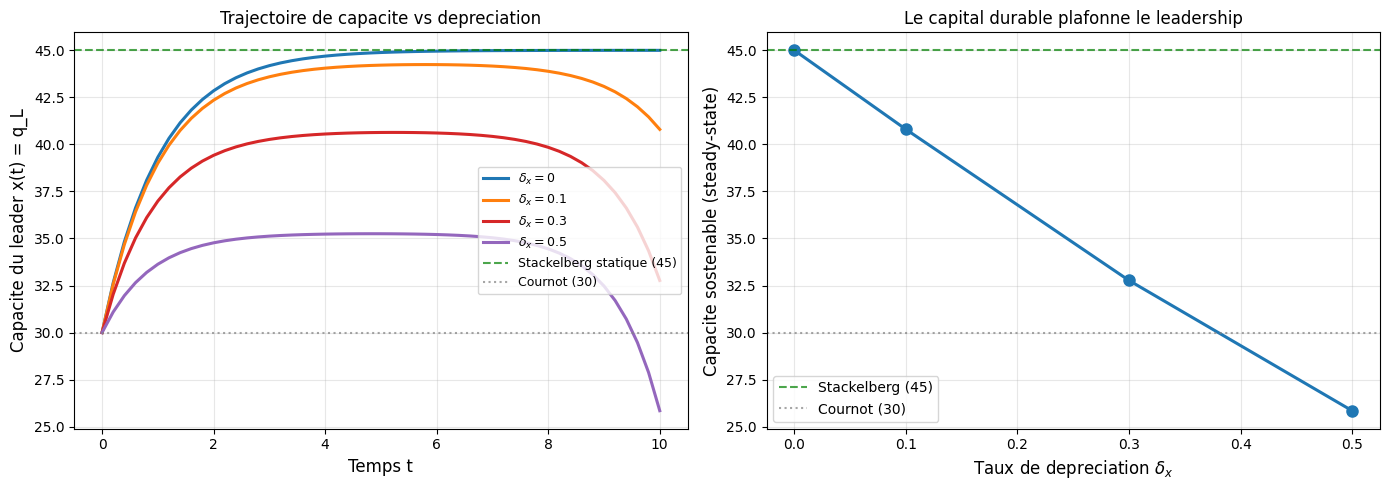

In [15]:
# Visualisation : trajectoires de capacite + steady-state vs depreciation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panneau gauche : trajectoire de capacite x(t) pour chaque delta_x
ax1 = axes[0]
colors_cap = {0.0: 'tab:blue', 0.1: 'tab:orange', 0.3: 'tab:red', 0.5: 'tab:purple'}
for dx_val, t_c, x_c, u_c, net_c, ok_c in results_cap:
    lbl = f'$\\delta_x = {dx_val:.1f}$' if dx_val > 0 else '$\\delta_x = 0$'
    ax1.plot(t_c, x_c, color=colors_cap[dx_val], linewidth=2.2, label=lbl)
ax1.axhline(q_stack_L, color='green', linestyle='--', linewidth=1.5, alpha=0.7,
            label=f'Stackelberg statique ({q_stack_L:.0f})')
ax1.axhline(q_cournot, color='gray', linestyle=':', linewidth=1.5, alpha=0.7,
            label=f'Cournot ({q_cournot:.0f})')
ax1.set_xlabel('Temps t', fontsize=12)
ax1.set_ylabel('Capacite du leader x(t) = q_L', fontsize=12)
ax1.set_title('Trajectoire de capacite vs depreciation', fontsize=12)
ax1.legend(loc='right', fontsize=9)
ax1.grid(alpha=0.3)

# Panneau droit : capacite steady-state (x_final) en fonction de delta_x
ax2 = axes[1]
dx_vals = [r[0] for r in results_cap]
x_finals = [r[2][-1] for r in results_cap]
ax2.plot(dx_vals, x_finals, 'o-', color='tab:blue', linewidth=2.2, markersize=8)
ax2.axhline(q_stack_L, color='green', linestyle='--', linewidth=1.5, alpha=0.7,
            label=f'Stackelberg ({q_stack_L:.0f})')
ax2.axhline(q_cournot, color='gray', linestyle=':', linewidth=1.5, alpha=0.7,
            label=f'Cournot ({q_cournot:.0f})')
ax2.set_xlabel('Taux de depreciation $\\delta_x$', fontsize=12)
ax2.set_ylabel('Capacite sostenable (steady-state)', fontsize=12)
ax2.set_title('Le capital durable plafonne le leadership', fontsize=12)
ax2.legend(loc='lower left', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Interpretation : pourquoi le capital durable plafonne le leadership

**Le levier $\delta_x$ discrimine la où $\delta$ (actualisation) ne le faisait pas.**
Dans le modele a cout d'ajustement (5.3), l'etat stationnaire est *toujours*
$q_{stack}$ : le $\delta$ d'actualisation ne fait que ralentir le ramp-up. Ici, la
capacite sostenable **decroit** avec $\delta_x$ :

- $\delta_x = 0$ : le capital **persiste** (pas d'erosion), le leader atteint et
  conserve $q_{stack} = 45$ -- cas limite ou l'engagement est gratuit a soutenir.
- $\delta_x = 0{,}5$ : le capital s'erode vite, le leader n'arrive plus a soutenir
  une capacite superieure a Cournot ($x^\star \approx 26 < 30$) -- son avantage
  Stackelberg s'effondre.

**C'est l'insight de Spence (1977) / Dixit (1980)** : l'engagement strategique par
capital durable n'est credible que dans la mesure ou le capital **persiste**. Une
capacite qui se deprecie vite n'effraie pas l'entrant -- il sait qu'elle s'evanouira.
A l'inverse, un capital a depreciation lente (usine, brevet, reseau) est un
engagement credible parce qu'il **survit** a la decision de l'entrant.

**Contraste final avec le cout d'ajustement.** Les deux mecanismes repondent a la
meme lecon (cellule precedente) -- un vrai dynamique exige un couplage
temporel -- mais l'encodent economiquement differemment :

| | Cout d'ajustement | Capital durable |
|---|---|---|
| **Ce qui persiste** | l'inertie (changer de cadence coute) | le capital installe (jusqu'a depreciation) |
| **Question economique** | a quelle vitesse monter en regime ? | quelle capacite soutenir face a l'erosion ? |
| **Litterature** | Hamermesh, investment-adjustment cost | Spence 1977, Dixit 1980 (entry deterrence) |

Les deux sont des formulations legitimes d'un Stackelberg dynamique non-degenere,
et le notebook gagne a les presenter cote a cote plutot qu'a les substituer.


## 6. Applications Economiques

### 6.1 Competition oligopolistique dynamique

Les modèles de Stackelberg sont utilises pour analyser :
- **Entree sur le marche** : l'incumbent comme leader
- **Capacite de production** : investissements irreversibles
- **Publicite** : campagnes marketing

### 6.2 Regulation

Le regulateur (leader) fixe des règles, les entreprises (followers) s'adaptent.

### 6.3 Commerce international

Pays exportateurs vs importateurs, guerres commerciales.

### 6.4 Transition : Vers des applications concretes

Après avoir explore la théorie des jeux differentiels et des equilibres de Stackelberg, nous allons maintenant appliquer ces concepts a des situations economiques reelles.

**Pourquoi ces applications sont-elles importantes ?**
- Les modèles théoriques prennent vie quand ils sont confrontes a des données reelles
- Les entreprises font face a des decisions d'entree, de capacite, de publicite
- Les regulateurs doivent comprendre les effets des politiques sur la concurrence

**Prochaine application : Jeu d'entree**
- Nous allons modeliser la decision d'une firme d'entrer sur un marche
- L'incumbent peut investir en capacite pour decourager l'entree
- C'est un exemple classique de **commitment strategy** (Spence, 1977)

Cette application illustre comment la théorie des jeux differentiels peut eclairer des decisions stratégiques majeures dans l'industrie.

In [16]:
# Application : Jeu d'entree avec couts fixes
print("Application : Jeu d'entree sur le marche")
print("="*60)

class EntryGame:
    """
    Modele d'entree avec cout fixe et engagement strategique.
    
    Incumbent peut investir en capacite (engagement)
    avant que l'entrant decide d'entrer.
    """
    
    def __init__(self, a: float = 100, b: float = 1,
                 c: float = 10, F: float = 200,
                 k: float = 5):  # Cout par unite de capacite
        self.a, self.b = a, b
        self.c = c  # Cout marginal
        self.F = F  # Cout fixe d'entree
        self.k = k  # Cout de capacite
    
    def incumbent_profit_monopoly(self, K: float) -> float:
        """Profit du monopole avec capacite K."""
        q_monopoly = (self.a - self.c) / (2 * self.b)
        q = min(q_monopoly, K)  # Contraint par la capacite
        P = self.a - self.b * q
        return (P - self.c) * q - self.k * K
    
    def duopoly_equilibrium(self, K: float) -> Tuple[float, float]:
        """Equilibre post-entree avec engagement de capacite (Dixit/Spence).

        L'incumbent a installe une capacite K et s'engage de maniere credible
        (irreversible) a produire a pleine capacite apres l'entree. C'est cette
        surcapacite AGRESSIVE qui ecrase le prix et rend l'entree non profitable
        au-dela d'un seuil K*. L'entrant anticipe q_inc = K et joue sa meilleure
        reponse de Cournot.

        Ce mecanisme (Spence 1977, Dixit 1979) est precisement ce qui donne a
        l'investissement en capacite son role de barriere a l'entree : sans
        l'engagement a produire K, augmenter la capacite au-dela du volume de
        Cournot n'aurait aucun effet sur le profit de l'entrant (le bug original
        figeait q_inc = q_ent = 30 pour K >= 30, soit un profit d'entrant constant
        a 700 qui ne croise jamais 0).
        """
        # L'incumbent produit a pleine capacite installee (engagement irreversible)
        q_inc = K
        # Meilleure reponse de Cournot du follower face a q_inc = K
        q_ent = max(0, (self.a - self.c - self.b * q_inc) / (2 * self.b))
        return q_inc, q_ent

    def entrant_profit(self, K: float) -> float:
        """Profit de l'entrant si entree."""
        q_inc, q_ent = self.duopoly_equilibrium(K)
        Q = q_inc + q_ent
        P = max(0, self.a - self.b * Q)
        return (P - self.c) * q_ent - self.F
    
    def entry_deterrence_capacity(self) -> float:
        """Capacite minimale pour deterrer l'entree."""
        # Trouver K tel que entrant_profit(K) = 0
        def objective(K):
            return abs(self.entrant_profit(K))
        
        result = minimize_scalar(objective, bounds=(0, 100), method='bounded')
        return result.x
    
    def analyze(self):
        """Analyse complete du jeu."""
        K_deter = self.entry_deterrence_capacity()
        
        # Profits selon les scenarios
        scenarios = {}
        
        # 1. Pas d'engagement, pas d'entree
        K_monopoly = 0
        pi_monopoly = self.incumbent_profit_monopoly(100)  # Capacite illimitee
        scenarios['Monopole sans investissement'] = (0, pi_monopoly, True)
        
        # 2. Entree et duopole
        K_duopoly = 30  # Capacite standard
        q_inc, q_ent = self.duopoly_equilibrium(K_duopoly)
        Q = q_inc + q_ent
        P = self.a - self.b * Q
        pi_duopoly = (P - self.c) * q_inc - self.k * K_duopoly
        scenarios['Duopole'] = (K_duopoly, pi_duopoly, False)
        
        # 3. Deterrence par capacite
        pi_deter = self.incumbent_profit_monopoly(K_deter)
        scenarios['Deterrence par capacite'] = (K_deter, pi_deter, True)
        
        return K_deter, scenarios


entry_game = EntryGame(a=100, b=1, c=10, F=200, k=5)
K_deter, scenarios = entry_game.analyze()

print(f"\nCapacite de deterrence: K* = {K_deter:.2f}")
print(f"Profit entrant si K = K*: {entry_game.entrant_profit(K_deter):.2f}")

print(f"\n{'Scenario':<30} {'Capacite':<12} {'Profit Inc.':<15} {'Monopole?'}")
print("-"*70)
for name, (K, pi, monopole) in scenarios.items():
    print(f"{name:<30} {K:<12.2f} {pi:<15.2f} {monopole}")

Application : Jeu d'entree sur le marche

Capacite de deterrence: K* = 61.72
Profit entrant si K = K*: 0.00

Scenario                       Capacite     Profit Inc.     Monopole?
----------------------------------------------------------------------
Monopole sans investissement   0.00         1525.00         True
Duopole                        30.00        750.00          False
Deterrence par capacite        61.72        1716.42         True


### Interpretation : Dissuasion d'entree et surcapacite strategique

Les resultats du jeu d'entree illustrent le concept de **barriere a l'entree par surcapacite** (Spence 1977 ; Dixit 1979).

**Le mecanisme de Dixit** : la dissuasion ne fonctionne que si l'incumbent s'engage de maniere credible (irreversible) a produire a pleine capacite K apres l'entree. L'entrant anticipe alors q_inc = K et joue sa meilleure reponse de Cournot q_ent = (90-K)/2. Le profit de l'entrant

$$\pi_{entrant}(K) = \left(\frac{90-K}{2}\right)^2 - F$$

est **strictement decroissant** en K et s'annule a la **capacite de dissuasion** interieure K* = 90 - 2√F ≈ 61.7 (pour F = 200). Au-dela de K*, l'entree n'est plus profitable.

**Analyse des scénarios** :

1. **Monopole sans investissement** (π=1525, reference contrefactuelle) : profit de monopole pur si l'entrant n'entrait pas. Mais sans capacite installee (K=0), l'entrant fait un profit de 1825 > 0 : il entre, et ce scenario n'est **pas** un equilibre.

2. **Duopole** (K=30, π=750) : capacite trop faible pour dissuader. L'entrant fait un profit de 700 > 0, il entre, et le profit de l'incumbent chute de 51 % par rapport au monopole.

3. **Dissuasion par capacite** (K*≈61.7, π=1716) : l'incumbent installe exactement la capacite K* qui rend l'entrant indifferant (π_entrant(K*) = 0). Au-dela, l'entree n'est plus rentable. L'entrant rationnel n'entre pas, et l'incumbent conserve son monopole.

**Pourquoi K* est interieur (et non un extremum)** : c'est precisement la signature que le solveur numerique (`minimize_scalar`) a trouve une **vraie racine** de π_entrant(K) = 0, et non un bord du domaine. Si le mecanisme de surcapacite n'etait pas modelise (q_inc fige au volume de Cournot), π_entrant resterait constant a 700 pour tout K >= 30 et le "solveur" retournerait le bord K=100 sans jamais atteindre π_entrant = 0 — un cas d'engrenage trivial ou le moteur SOTA (optimisation 1-D) n'apporte rien.

> **Theoreme de Spence-Dixit (1977-1979)** : l'incumbent peut dissuader l'entree en s'engageant sur une surcapacite K* calculee pour annuler exactement le profit espere de l'entrant. L'investissement est credible parce qu'irreversible et observable ; il n'a pas besoin d'etre utilise en totalite a l'equilibre (l'entrant n'entre pas), mais sa menace suffit.

> **Theoreme de Spence (1977)** : Dans un jeu d'entree, l'incumbent peut deterrer l'entree en s'engageant sur une capacite suffisante, même si cette capacite n'est pas utilisee en totalite a l'equilibre.

## 7. Exercices

### Exercice 1 : Stackelberg asymetrique

Analysez un duopole de Stackelberg ou le leader et le follower ont des couts marginaux différents ($c_L \neq c_F$).

### Exercice 2 : Jeu LQ a somme nulle

Implementez et resolvez un jeu differentiel a somme nulle (poursuite-evasion).

### Exercice 3 : Commitment value

Calculez la "valeur de l'engagement" : la différence de profit pour le leader entre Stackelberg et Cournot.

### Exercice 4 : Stackelberg a 3 joueurs

Modelisez un jeu avec un leader et deux followers qui reagissent simultanement.

In [17]:
# Espace pour les exercices

# Exercice 3 : Valeur de l'engagement
def commitment_value(demand: LinearDemand, firm_L: Firm, firm_F: Firm) -> float:
    """
    Calcule la valeur de l'engagement = profit_Stackelberg - profit_Cournot
    pour le leader.
    """
    # Exercice: Calculer le profit du leader en Cournot et en Stackelberg
    # puis retourner la difference.
    #
    # Etapes:
    # 1. Calculer l'equilibre de Cournot avec cournot_equilibrium()
    # 2. Calculer le profit du leader en Cournot
    # 3. Calculer l'equilibre de Stackelberg avec stackelberg_equilibrium()
    # 4. Calculer le profit du leader en Stackelberg
    # 5. Retourner profit_stackelberg - profit_cournot
    pass

# Test (decommentez apres implementation)
# value = commitment_value(demand, firm_A, firm_B)
# print(f"Valeur de l'engagement pour le leader: {value:.2f}")
print("Exercice a completer : Valeur de l engagement (Stackelberg vs Cournot)")


Exercice a completer : Valeur de l engagement (Stackelberg vs Cournot)


### Exercice 5 : Jeu de poursuite (Pursuit-Evasion)

Modelisez un jeu de poursuite simple en 2D. Un poursuivant (P) a vitesse v_p et un evasif (E) a vitesse v_e < v_p.
L'objectif de P est de capturer E (distance < epsilon) ; E veut maximiser le temps de capture.

- **Étape 1** : Définir les equations differentielles du mouvement
- **Étape 2** : Implementer une trajectoire de poursuite (P vise E a chaque instant)
- **Étape 3** : Calculer le temps de capture et verifier qu'il est fini quand v_p > v_e

*Indice* : La stratégie optimale de P est de se diriger directement vers E (ligne droite).

In [18]:
# Exercice 5 : Jeu de poursuite (Pursuit-Evasion)
# TODO etudiant : modeliser la poursuite en 2D
# Etape 1 : equations du mouvement
# Etape 2 : simulation Euler
# Etape 3 : temps de capture
def simulate_pursuit(v_p: float, v_e: float, pos_p: list, pos_e: list, dt: float = 0.01) -> dict:
    return {"capture_time": None, "trajectory": []}  # TODO etudiant

print("Exercice a completer")

Exercice a completer


***

## Exercice 6 : Jeu differentiel linear-quadratic

**Objectifs** :

1. Formuler un jeu differentiel LQ
2. Resoudre les equations de Hamilton-Jacobi-Bellman
3. Comparer solution en boucle ouverte vs feedback

**Contexte** : Duopole avec ajustement dynamique des prix. Chaque firme ajuste son prix p_i(t) pour maximiser son profit integre, avec cout d'ajustement.

**Questions** :

1. Ecrivez les equations HJB pour chaque joueur
2. Quelle est la stratégie feedback d'equilibre ?
3. Comment le cout d'ajustement affecte-t-il la dynamique ?


In [19]:
# Exercice 6 : Duopole dynamique LQ
import numpy as np
from scipy.integrate import solve_ivp

# Exercice: Definir les parametres du duopole
# RHO = 0.95  # Facteur d'actualisation
# ALPHA = 1.0  # Sensibilite de la demande
# C = 0.5  # Cout marginal
# KAPPA = 0.1  # Cout d'ajustement

# Exercice: Formuler le probleme LQ
# Etat: x(t) = [p1(t), p2(t)]
# Controle: u_i(t) = dp_i/dt
# Dynamique: dx/dt = u
# Objectif: max integral exp(-rho*t) * [profit_i - kappa*u_i^2] dt

# Exercice: Resoudre les equations HJB
# Les strategies feedback sont lineaires: u_i = K * x
# Les equations Riccati donnent K
# def solve_lq_game(A, B, Q, R, rho):
#     # Resoudre le systeme d'equations de Riccati couplees
#     ...

# Exercice: Simuler la trajectoire d'equilibre
# def simulate_equilibrium(x0, T, K):
#     ...

# Exercice: Comparer avec la solution en boucle ouverte (Nash OL)
# print("Solution feedback vs open-loop:")
# ...
print("Exercice a completer : Duopole dynamique LQ (equations differentielles)")


Exercice a completer : Duopole dynamique LQ (equations differentielles)


## 8. Transition vers les jeux cooperatifs

### Du leadership a la cooperation

Dans ce notebook, nous avons vu comment un **leader** peut exploiter son avantage stratégique (Stackelberg) en s'engageant avant ses concurrents.

Mais que se passe-t-il si les joueurs decident de **cooperer** plutot que de se faire concurrence ?

### La question de la "valeur" d'une coalition

Dans les jeux cooperatifs (notebook suivant), on s'interesse a :
- **Formation de coalitions** : quels groupes se forment ?
- **Repartition des gains** : comment partager le surplus de la cooperation ?
- **Stabilite** : pourquoi certaines coalitions tiennent et d'autres eclatent ?

### Du Stackelberg a Shapley

| Concept non-cooperatif | Equivalent cooperatif |
|-----------------------|----------------------|
| Avantage du leader | Contribution marginale |
| Equilibre de Nash | Core (stabilite) |
| Best response | Fonction caractéristique |
| Engagement | Formation de coalition |

### Exemple : Course publicitaire → Alliance marketing

Dans le jeu LQ de course publicitaire (section 4), les deux firmes depensent des ressources pour se neutraliser mutuellement.

**Alternative cooperative** : Former une alliance marketing ou les deux firmes coordonnent leurs efforts. La **valeur de Shapley** permet alors de repartir equitablement les gains de cette cooperation.

Cette transition naturelle nous amene au notebook 14 sur les **jeux cooperatifs**.

***

## 9. Resume et Points Cles

### Ce que nous avons appris

1. **Jeux dynamiques** : les decisions se deroulent dans le temps
2. **Boucle ouverte vs fermee** : engagement vs adaptation
3. **Stackelberg** : avantage du premier joueur par engagement
4. **Jeux LQ** : solutions analytiques via equations de Riccati
5. **Applications** : oligopoles, entree, regulation

### Formules cles

| Concept | Formule |
|---------|--------|
| Reaction follower (duopole lineaire) | $q_F(q_L) = \frac{a - c_F - b \cdot q_L}{2b}$ |
| Stackelberg (leader) | $q_L^* = \frac{a - 2c_L + c_F}{2b}$ |
| Feedback LQ | $u^*(x,t) = -K(t) \cdot x$ |
| Valeur engagement | $\Delta \pi = \pi_{Stack} - \pi_{Cournot}$ |

### Comparaison des equilibres

| Aspect | Cournot | Stackelberg |
|--------|---------|-------------|
| Timing | Simultane | Séquentiel |
| Output total | Plus bas | Plus haut |
| Prix | Plus haut | Plus bas |
| Profit leader | Standard | Avantage |
| Bien-etre | Moindre | Meilleur |

***

**Notebook suivant** : [GameTheory-15-CooperativeGames-Python](GameTheory-15-CooperativeGames-Python.ipynb) - Jeux cooperatifs, valeur de Shapley et formation de coalitions

## References

- **Isaacs, R. (1965).** *Differential Games: A Mathematical Theory with Applications to Warfare and Pursuit, Control and Optimization.* Wiley. -- **papier fondateur des differential games**. Équation d'Isaacs, conditions aux limites obliques pour les fonctions valeur, jeu à somme nulle à temps continu, et poursuite-évasion. **Mapping direct au carnet 14**.
- **Basar, T. & Olsder, G. J. (1999).** *Dynamic Noncooperative Game Theory.* SIAM Classics in Applied Mathematics 23, 2ᵉ éd. -- **référence moderne en jeux dynamiques non-coopératifs**. Patterns d'information (open-loop, closed-loop, feedback), LQ games à temps continu, Stackelberg dynamique, déterminisme et stochastique. **Mapping direct au carnet 14** (sections 4-5 Stackelberg / LQ).
- **Evans, L. C. (2010).** *Partial Differential Equations.* American Mathematical Society GSM 19, 2ᵉ éd. -- **référence PDE** couvrant la théorie de viscosité des équations Hamilton-Jacobi-Bellman, méthode des caractéristiques, solutions de viscosité. **Prérequis mathématique** du carnet 14.
- **Bressan, A. (2011).** *Noncooperative differential games. A tutorial.* Milan Journal of Mathematics 79(2), 357-427, DOI 10.1007/s00032-011-0163-6. -- **panorama des difficultés théoriques** des differential games : fonctions valeur non-lipschitziennes, problèmes mal posés, stratégies non-régulières. **Mapping direct au carnet 14** (section 4 jeux LQ + Stackelberg dynamique).
- **Bardi, M. & Capuzzo-Dolcetta, I. (1997).** *Optimal Control and Viscosity Solutions of Hamilton-Jacobi-Bellman Equations.* Birkhauser. -- **référence historique sur la théorie de viscosité appliquée au contrôle optimal**, conditions aux limites, approximation par schéma numérique, conditions de Dirichlet. **Prérequis numérique** du carnet 14 (les résolutions reposent sur le schéma explicite de Bellman, valide en viscosité).
- **Fleming, W. H. & Rishel, R. W. (1975).** *Deterministic and Stochastic Optimal Control.* Springer. -- **référence fondatrice** sur les fonctions valeur en contrôle optimal, théorie de sélection mesurable, décomposition en problèmes local-globaux. **Prérequis épistémique** du carnet 14 (ce qu'Isaacs 1965 suppose implicitement sur la régularité des fonctions valeur).



## Conclusion

Ce notebook a presente les **jeux differentiels** et les **equilibres de Stackelberg**, des modèles dynamiques ou les joueurs ajustent leurs stratégies en continu.

### Résultats cles

| Modèle | Leader | Follower | Industrie | Insight |
|--------|--------|----------|-----------|---------|
| **Cournot** (statique) | q=30, pi=900 | q=30, pi=900 | 1800 | Symetrie, optimum collectif |
| **Stackelberg** (dynamique) | q=45, pi=1012 | q=22.5, pi=506 | 1519 | Avantage leader +112, perte follower -394 |

### Lecons principales

1. **L'avantage du premier joueur** : le leader Stackelberg gagne +12.5% par rapport a Cournot, mais le follower perd -43.75%. L'industrie dans son ensemble est **moins efficace** (1519 vs 1800).

2. **Jeux LQ et equation de Riccati** : les stratégies feedback sont lineaires (u_i = -K_i * x), avec K_1(0)=0.5450 et K_2(0)=-0.5450 dans la course publicitaire. La dynamique est stable.

3. **Dissuasion d'entree** : en installant la capacite de dissuasion K*≈61.7 (racine interieure), le monopole dissuade l'entree (π_entrant=0) et obtient un profit de 1716.42, superieur a la reference contrefactuelle du monopole sans investissement (1525).

**Suite** : [GT-15 - Jeux cooperatifs](GameTheory-15b-Lean-CooperativeGames-Lean.ipynb) | [Retour au sommaire](README.md)